# 06 — Инфраструктура и физические шоки

Цель: описать таблицы инфраструктурной ветки (добыча и платформы на шельфе Мексиканского залива, ураганы,
офшорные трубопроводы, НПЗ, трубопроводы GEM, кандидаты из OSM), измерить их качество и понять, что из них
годится в узлы/рёбра гетерогенного графа и в признаки физических шоков для прогноза недельного inventory surprise.

Файлы: все parquet из `eda/data/processed/infrastructure/` (BOEM, BSEE, NHC HURDAT2, EIA refinery capacity,
GEM GOIT, OSM) и `eia/eia_weekly_features.parquet` (колонка `crude_production`) для сравнения.
Определения и единицы взяты из `src/data/{boem_client,bsee_client,noaa_hurdat,gem_goit,overpass_client,refinery_capacity}.py`
и `jup_files/data/03_infrastructure_data.ipynb`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle

import eda_utils as u

u.setup_style()
INF = "infrastructure/"

## 0. Состав данных

Дату выгрузки берём из времени изменения файлов: всё, что датировано позже неё, заведомо ошибочно.

In [2]:
files = sorted((u.DATA / "infrastructure").glob("*.parquet"))
rows = []
for f in files:
    df = pd.read_parquet(f)
    rows.append(
        {"файл": f.name, "строк": len(df), "колонок": df.shape[1], "размер, МБ": round(f.stat().st_size / 1e6, 1)}
    )
overview = pd.DataFrame(rows)
SNAPSHOT = pd.Timestamp(max(f.stat().st_mtime for f in files), unit="s").normalize()
print(f"Файлов: {len(files)}; дата выгрузки (mtime): {SNAPSHOT.date()}")
overview

Файлов: 21; дата выгрузки (mtime): 2026-11-04


,файл,строк,колонок,"размер, МБ"
0,boem_platforms_current.parquet,1315,6,0.0
1,bsee_offshore_crude_pipelines.parquet,7030,48,5.0
2,bsee_offshore_pipelines.parquet,21314,48,16.2
3,bsee_pipeline_history_events.parquet,85139,8,3.8
4,bsee_platform_history.parquet,7092,33,0.6
5,bsee_production_by_complex_month_2015plus.parquet,150465,10,0.9
6,bsee_production_by_structure_2015plus.parquet,159917,17,1.0
7,eia_refineries_model_ready.parquet,1561,22,0.1
8,eia_refineries_territories_other.parquet,3,22,0.0
9,eia_refinery_capacity_long.parquet,43099,13,0.1


In [3]:
prod_s = u.load(INF + "bsee_production_by_structure_2015plus.parquet")
prod_c = u.load(INF + "bsee_production_by_complex_month_2015plus.parquet")
plat = u.load(INF + "bsee_platform_history.parquet")
boem = u.load(INF + "boem_platforms_current.parquet")
pipes = u.load(INF + "bsee_offshore_pipelines.parquet")
pipes_crude = u.load(INF + "bsee_offshore_crude_pipelines.parquet")
pev = u.load(INF + "bsee_pipeline_history_events.parquet")
hur = u.load(INF + "nhc_hurdat2_atlantic_2015_2025.parquet")
ref = u.load(INF + "eia_refineries_model_ready.parquet")
ref_other = u.load(INF + "eia_refineries_territories_other.parquet")
ref_long = u.load(INF + "eia_refinery_capacity_long.parquet")
gem_all = u.load(INF + "gem_pipelines_all.parquet")
gem_us = u.load(INF + "gem_pipelines_us.parquet")
gem_t = u.load(INF + "gem_oil_pipelines_temporal.parquet")
own_all = u.load(INF + "gem_pipeline_ownership_all.parquet")
own_us = u.load(INF + "gem_pipeline_ownership_us.parquet")
own_snap = u.load(INF + "gem_pipeline_ownership_us_snapshot_2026_10.parquet")
ent = u.load(INF + "gem_entities.parquet")
ent_own = u.load(INF + "gem_entity_ownership.parquet")
osm_ref = u.load(INF + "osm_refinery_candidates.parquet")
osm_tank = u.load(INF + "osm_oil_storage_tank_candidates.parquet")
eia = u.load("eia/eia_weekly_features.parquet")

**Вывод.** В папке 21 parquet-файл (а не 25): BSEE — 6, BOEM — 1, HURDAT — 1, EIA refinery — 3, GEM — 8, OSM — 2.
Самые тяжёлые — `bsee_offshore_pipelines` и `gem_pipelines_all` (в них хранится геометрия в виде JSON-строк).

## 1. Добыча на шельфе Мексиканского залива (BSEE)

Единицы (BSEE Production by Platform): `bopd` — нефть, баррелей в сутки (среднесуточно за месяц), `mcfpd` — газ,
тыс. куб. футов в сутки, `boepd` — нефтяной эквивалент, `producing_wells` — действующие скважины.
`production_date` — последний день месяца. Таблица по комплексам (`complex_id_num`) — агрегат таблицы по
сооружениям (`structure_number`), построенный `BseeClient.aggregate_production_by_complex`.

### 1.1 Регионы и полнота последних месяцев

In [4]:
REGION = {"G": "Мексиканский залив", "P": "Тихоокеанский шельф", "Y": "Аляска"}
reg_month = prod_s.groupby(["production_date", "region_code"])["bopd"].sum().unstack()
codes = list(reg_month.columns)
reg_tab = pd.DataFrame(
    {
        "регион": [REGION.get(c, c) for c in codes],
        "строк": prod_s["region_code"].value_counts().reindex(codes).to_numpy(),
        "комплексов": prod_s.groupby("region_code")["complex_id_num"].nunique().reindex(codes).to_numpy(),
        "месяцев": reg_month.notna().sum().to_numpy(),
        "нефть 2015–2025, тыс. барр./сут": (reg_month.loc[reg_month.index.year <= 2025].mean() / 1e3).round(1).to_numpy(),
        "самый частый оператор": prod_s.groupby("region_code")["pf_operator"]
        .agg(lambda x: x.mode().iloc[0])
        .reindex(codes)
        .to_numpy(),
    },
    index=pd.Index(codes, name="region_code"),
)
reg_tab

,регион,строк,комплексов,месяцев,"нефть 2015–2025, тыс. барр./сут",самый частый оператор
region_code,,,,,,
G,Мексиканский залив,157300,1625,141,1742.5,"W & T Offshore, Inc."
P,Тихоокеанский шельф,2479,22,141,13.8,"DCOR, L.L.C."
Y,Аляска,138,1,138,8.1,"Hilcorp Alaska, LLC"


In [5]:
gom = prod_s[prod_s["region_code"].eq("G")].copy()
gom["month"] = gom["production_date"].dt.to_period("M")
monthly = gom.groupby("month").agg(
    oil_bopd=("bopd", "sum"),
    gas_mcfpd=("mcfpd", "sum"),
    wells=("producing_wells", "sum"),
    structures=("structure_number", "size"),
    operators=("pf_operator", "nunique"),
)
monthly["complexes_oil"] = gom[gom["bopd"] > 0].groupby("month")["complex_id_num"].nunique()
rows_ratio = (monthly["structures"] / monthly["structures"].shift(1).rolling(6, min_periods=1).median()).astype(float)
oil_ratio = (monthly["oil_bopd"] / monthly["oil_bopd"].shift(1).rolling(6, min_periods=1).median()).astype(float)
monthly["complete"] = ~((rows_ratio < 0.5) & (oil_ratio < 0.5))
print("Неполные месяцы (и строк, и нефти < 50% медианы шести предыдущих):", list(monthly.index[~monthly["complete"]].astype(str)))
step = monthly["structures"].diff()
print(f"Крупнейшее падение числа строк в полных месяцах: {int(step[monthly['complete']].min())} в {step[monthly['complete']].idxmin()}")
monthly.tail(6)

Неполные месяцы (и строк, и нефти < 50% медианы шести предыдущих): ['2026-09']
Крупнейшее падение числа строк в полных месяцах: -138 в 2024-02


,oil_bopd,gas_mcfpd,wells,structures,operators,complexes_oil,complete
month,,,,,,,
2026-04,2124652,2245791,1663,593,42,308,True
2026-05,1924192,1959227,1680,592,41,311,True
2026-06,2000335,2057236,1663,592,42,303,True
2026-07,1954745,2047782,1671,589,42,302,True
2026-08,1995185,2037680,1627,586,41,300,True
2026-09,238675,343760,602,176,16,110,False


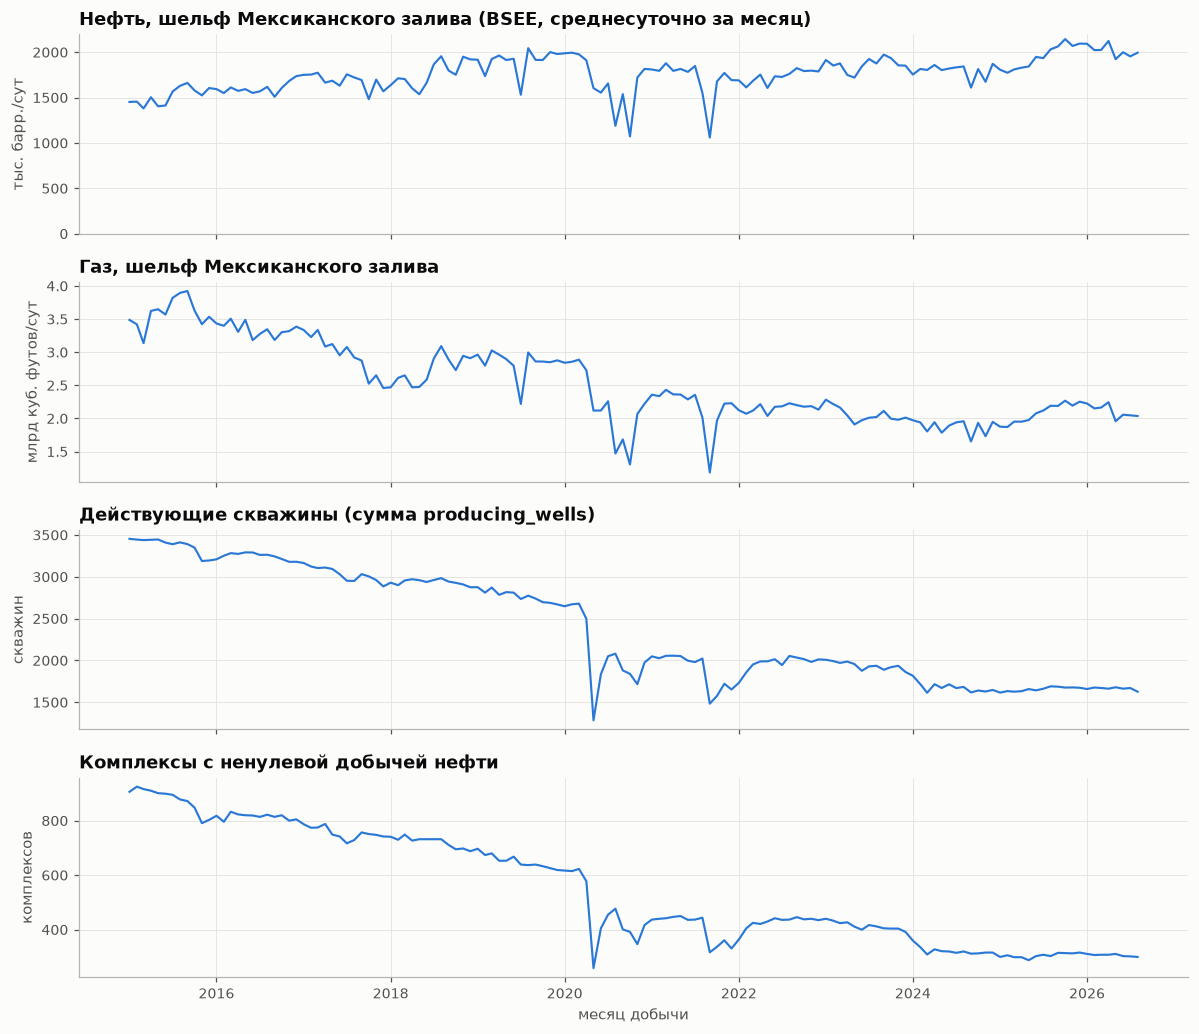

In [6]:
gm = monthly[monthly["complete"]].copy()
gm["oil_kbd"] = gm["oil_bopd"] / 1e3
gm["gas_bcfd"] = gm["gas_mcfpd"] / 1e6
LAST_FULL = gm.index.max()

fig, axes = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)
x = gm.index.to_timestamp()
panels = [
    ("oil_kbd", "тыс. барр./сут", "Нефть, шельф Мексиканского залива (BSEE, среднесуточно за месяц)"),
    ("gas_bcfd", "млрд куб. футов/сут", "Газ, шельф Мексиканского залива"),
    ("wells", "скважин", "Действующие скважины (сумма producing_wells)"),
    ("complexes_oil", "комплексов", "Комплексы с ненулевой добычей нефти"),
]
for ax, (col, ylabel, title) in zip(axes, panels):
    ax.plot(x, gm[col], color=u.SERIES[0])
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].set_ylim(bottom=0)
axes[-1].set_xlabel("месяц добычи")
fig.tight_layout()
plt.show()

In [7]:
year_prod = gm.groupby(gm.index.year).agg(
    месяцев=("oil_kbd", "size"),
    нефть_тыс_барр_сут=("oil_kbd", "mean"),
    газ_млрд_фут3_сут=("gas_bcfd", "mean"),
    скважин=("wells", "mean"),
    комплексов_с_нефтью=("complexes_oil", "mean"),
    операторов=("operators", "mean"),
)
year_prod.index.name = "год"
year_prod.round(2)

,месяцев,нефть_тыс_барр_сут,газ_млрд_фут3_сут,скважин,комплексов_с_нефтью,операторов
год,,,,,,
2015,12,1515.19,3.59,3380.17,878.67,89.08
2016,12,1600.29,3.34,3245.25,815.33,79.25
2017,12,1682.48,2.96,3034.75,754.92,74.00
2018,12,1759.02,2.73,2938.08,722.25,71.33
2019,12,1898.25,2.84,2773.17,651.50,68.25
2020,12,1669.11,2.21,2096.92,465.50,63.83
2021,12,1707.13,2.18,1889.83,406.58,62.25
2022,12,1731.56,2.16,1965.17,426.58,60.67
2023,12,1865.15,2.06,1938.92,414.08,56.92


### 1.2 Концентрация операторов

Доля оператора — его доля в нефти залива за месяц (по `pf_operator`, юрлицо BSEE, не корпоративная группа).
HHI = сумма квадратов долей в процентах (0–10 000; > 2500 — высокая концентрация по шкале DOJ).

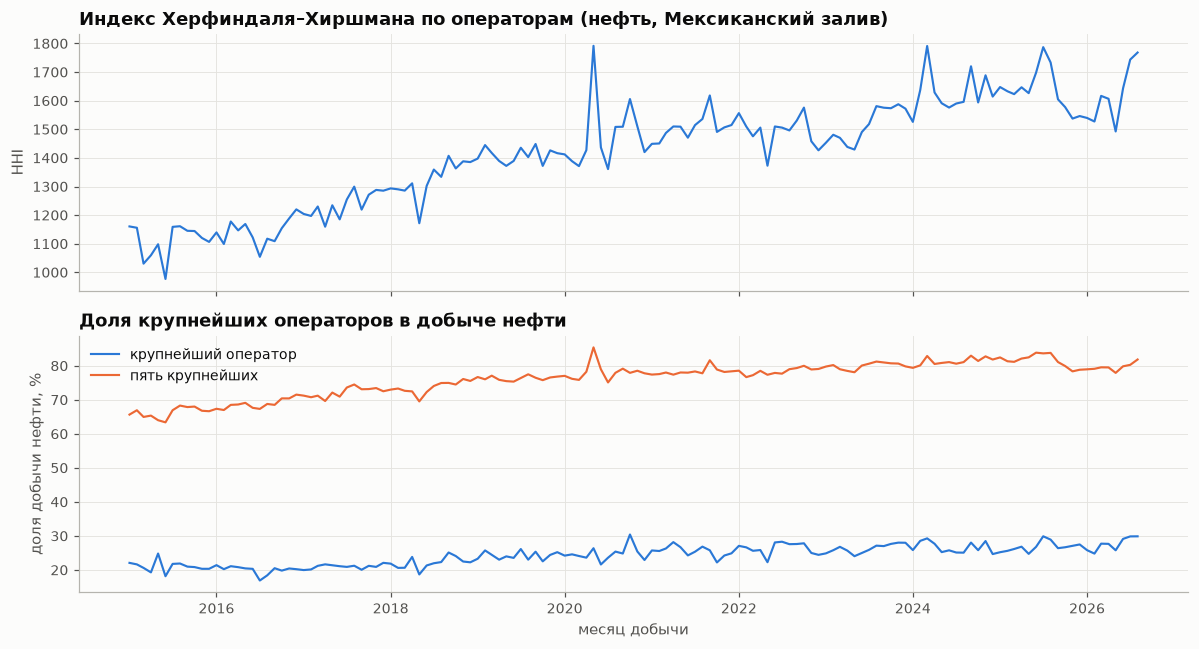

In [8]:
gom_c = gom[gom["month"].isin(gm.index)].copy()
op_m = gom_c.groupby(["month", "pf_operator"])["bopd"].sum()
op_m = op_m[op_m > 0]
share_m = op_m / op_m.groupby(level="month").transform("sum") * 100
conc = pd.DataFrame(
    {
        "hhi": (share_m**2).groupby(level="month").sum(),
        "top1": share_m.groupby(level="month").max(),
        "top5": share_m.groupby(level="month").apply(lambda s: s.nlargest(5).sum()),
    }
)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
xc = conc.index.to_timestamp()
axes[0].plot(xc, conc["hhi"], color=u.SERIES[0])
axes[0].set_ylabel("HHI")
axes[0].set_title("Индекс Херфиндаля–Хиршмана по операторам (нефть, Мексиканский залив)")
axes[1].plot(xc, conc["top1"], label="крупнейший оператор")
axes[1].plot(xc, conc["top5"], label="пять крупнейших")
axes[1].set_ylabel("доля добычи нефти, %")
axes[1].set_title("Доля крупнейших операторов в добыче нефти")
axes[1].legend()
axes[1].set_xlabel("месяц добычи")
fig.tight_layout()
plt.show()

In [9]:
op_y = gom_c.assign(year=gom_c["month"].dt.year).groupby(["year", "pf_operator"])["bopd"].sum()
op_y = op_y[op_y > 0]
sh_y = op_y / op_y.groupby(level="year").transform("sum") * 100
year_conc = pd.DataFrame(
    {
        "HHI": (sh_y**2).groupby(level="year").sum().round(0),
        "доля топ-1, %": sh_y.groupby(level="year").max().round(1),
        "топ-1 оператор": sh_y.groupby(level="year").idxmax().map(lambda t: t[1]),
        "доля топ-5, %": sh_y.groupby(level="year").apply(lambda s: s.nlargest(5).sum()).round(1),
        "операторов с нефтью": sh_y.groupby(level="year").size(),
    }
)
year_conc

,HHI,"доля топ-1, %",топ-1 оператор,"доля топ-5, %",операторов с нефтью
year,,,,,
2015,1092.0,20.6,Shell Offshore Inc.,65.7,75
2016,1130.0,19.4,Shell Offshore Inc.,68.8,66
2017,1226.0,19.8,BP Exploration & Production Inc.,72.2,61
2018,1308.0,20.6,Shell Offshore Inc.,73.7,60
2019,1398.0,24.2,Shell Offshore Inc.,76.3,59
2020,1453.0,24.5,Shell Offshore Inc.,77.8,58
2021,1484.0,25.1,Shell Offshore Inc.,78.2,55
2022,1479.0,26.4,Shell Offshore Inc.,78.4,49
2023,1510.0,26.3,Shell Offshore Inc.,80.0,48


In [10]:
top_ops = sh_y.loc[2025].nlargest(10).round(1).rename("доля нефти 2025, %").to_frame()
top_ops["нефть 2025, тыс. барр./сут"] = (op_y.loc[2025].reindex(top_ops.index) / 12 / 1e3).round(1)
top_ops

,"доля нефти 2025, %","нефть 2025, тыс. барр./сут"
pf_operator,,
Shell Offshore Inc.,26.8,521.2
BP Exploration & Production Inc.,21.6,420.5
Chevron U.S.A. Inc.,15.7,305.4
Anadarko Petroleum Corporation,11.5,223.9
Murphy Exploration & Production Company - USA,6.0,116.0
Hess Corporation,2.5,48.9
Talos QN Exploration LLC,1.9,37.9
"Talos Energy Ventures, LLC",1.8,34.6
Woodside Energy (GOM) Inc.,1.7,33.4


### 1.3 Крупнейшие комплексы и согласованность агрегатов

In [11]:
gom_complex_ids = set(gom["complex_id_num"].unique())
c25 = prod_c[prod_c["production_date"].dt.year.eq(2025) & prod_c["complex_id_num"].isin(gom_complex_ids)]
top_c = c25.groupby("complex_id_num").agg(
    нефть_тыс_барр_сут=("bopd", "mean"),
    газ_млн_фут3_сут=("mcfpd", "mean"),
    скважин=("producing_wells", "mean"),
    сооружений=("structure_count", "max"),
    оператор=("primary_operator", "last"),
)
top_c["нефть_тыс_барр_сут"] /= 1e3
top_c["газ_млн_фут3_сут"] /= 1e3
loc_info = gom.groupby("complex_id_num").agg(
    участок=("area_code", "last"), блок=("block_number", "last"), сооружение=("structure_name", "last")
)
top_c = top_c.join(loc_info).sort_values("нефть_тыс_барр_сут", ascending=False)
top_c["доля залива, %"] = top_c["нефть_тыс_барр_сут"] / top_c["нефть_тыс_барр_сут"].sum() * 100
top_c["накопл. доля, %"] = top_c["доля залива, %"].cumsum()
cum = top_c["накопл. доля, %"].to_numpy()
print(
    f"Комплексов с нефтью > 0 в 2025: {(top_c['нефть_тыс_барр_сут'] > 0).sum()}; "
    f"50% нефти дают {int(np.searchsorted(cum, 50) + 1)}, 90% — {int(np.searchsorted(cum, 90) + 1)} комплексов"
)
num_cols = top_c.select_dtypes("number").columns
top_c.head(15).assign(**{c: top_c[c].head(15).round(1) for c in num_cols})

Комплексов с нефтью > 0 в 2025: 348; 50% нефти дают 12, 90% — 36 комплексов


,нефть_тыс_барр_сут,газ_млн_фут3_сут,скважин,сооружений,оператор,участок,блок,сооружение,"доля залива, %","накопл. доля, %"
complex_id_num,,,,,,,,,,
1101,148.1,124.6,22.6,1,BP Exploration & Production Inc.,MC,778,A(Thunder Horse,7.6,7.6
2440,119.9,25.6,25.0,1,Chevron U.S.A. Inc.,WR,718,A(Jack St. Malo,6.2,13.8
2623,105.8,63.2,15.2,1,Shell Offshore Inc.,MC,437,A (Appomattox),5.4,19.2
2665,87.8,20.4,11.7,1,BP Exploration & Production Inc.,GC,780,A (Argos),4.5,23.7
2385,77.3,91.1,20.6,1,Shell Offshore Inc.,MC,807,B (Olympus),4.0,27.7
1223,75.5,67.6,27.2,1,BP Exploration & Production Inc.,GC,787,A (Atlantis),3.9,31.6
70004,71.1,81.5,22.1,1,Shell Offshore Inc.,MC,809,A (Ursa),3.7,35.2
1665,67.4,65.1,9.8,1,Anadarko Petroleum Corporation,GC,680,A(Constitution),3.5,38.7
2008,66.9,84.1,24.2,1,Shell Offshore Inc.,AC,857,A (Perdido),3.4,42.1


In [12]:
agg_s = (
    prod_s.groupby(["complex_id_num", "production_date"])
    .agg(
        bopd=("bopd", "sum"),
        mcfpd=("mcfpd", "sum"),
        boepd=("boepd", "sum"),
        bwpd=("bwpd", "sum"),
        producing_wells=("producing_wells", "sum"),
        structure_count=("structure_number", "nunique"),
    )
    .reset_index()
)
chk = prod_c.merge(agg_s, on=["complex_id_num", "production_date"], how="outer", suffixes=("_c", "_s"), indicator=True)
consistency = {
    "строк в таблице комплексов": len(prod_c),
    "групп комплекс×месяц из таблицы сооружений": len(agg_s),
    "совпало по ключу": int((chk["_merge"] == "both").sum()),
    "дубликатов ключа в таблице комплексов": int(prod_c.duplicated(["complex_id_num", "production_date"]).sum()),
    "дубликатов строк в таблице сооружений": int(prod_s.duplicated().sum()),
}
for col in ["bopd", "mcfpd", "boepd", "bwpd", "producing_wells", "structure_count"]:
    consistency[f"max |расхождение| {col}"] = float((chk[f"{col}_c"] - chk[f"{col}_s"]).abs().max())
consistency["значения operator_count"] = sorted(prod_c["operator_count"].unique().tolist())
consistency["комплексов в >1 регионе"] = int((prod_s.groupby("complex_id_num")["region_code"].nunique() > 1).sum())
nz = prod_s[prod_s["mcfpd"] > 0]
consistency["медиана mcfpd/(boepd−bopd), куб. футов на барр. н. э. ×1000"] = float(
    ((nz["mcfpd"]) / (nz["boepd"] - nz["bopd"])).median()
)
pd.Series(consistency, name="значение").to_frame()

,значение
строк в таблице комплексов,150465
групп комплекс×месяц из таблицы сооружений,150465
совпало по ключу,150465
дубликатов ключа в таблице комплексов,0
дубликатов строк в таблице сооружений,0
max |расхождение| bopd,0.0
max |расхождение| mcfpd,0.0
max |расхождение| boepd,0.0
max |расхождение| bwpd,0.0
max |расхождение| producing_wells,0.0


**Вывод.**
- Таблицы добычи покрывают не только залив: регион `G` — 157 300 строк и 1 625 комплексов, средняя добыча
  1 742,5 тыс. б/с (2015–2025), но есть также Тихоокеанский шельф (`P`, 22 комплекса, 13,8 тыс. б/с) и один
  комплекс Аляски (`Y`, Hilcorp, 8,1 тыс. б/с). В таблице по комплексам `region_code` нет — регион фильтруется
  только через таблицу сооружений.
- Последний месяц 2026-09 неполный: 176 строк вместо ~586 и 239 тыс. б/с вместо ~2 000 → исключён; полные данные
  до 2026-08. В 2024-02 из таблицы разом пропали 138 строк (в основном сооружения с нулевой добычей) — это
  ступенька в числе сооружений, не в объёмах.
- Добыча нефти выросла с 1 515 тыс. б/с (2015) до 1 898 (2019), упала до 1 669 в 2020 (COVID + ураганы) и дошла до
  1 946 в 2025 и 2 018 за январь–август 2026. Газ, наоборот, снизился с 3,59 до 2,08 млрд куб. футов/сут; действующих
  скважин стало вдвое меньше (3 380 → 1 657), комплексов с нефтью — 879 → 305. Добыча концентрируется на
  немногих глубоководных хабах: в 2025 г. 12 комплексов дают 50% нефти, 36 — 90% (из 348). Крупнейший —
  Thunder Horse (BP, MC 778), 148 тыс. б/с, или 7,6%.
- Концентрация операторов растёт: HHI 1 092 → 1 625 (2015 → 2025), доля Shell 20,6% → 26,8%, топ-5 65,7% → 81,5%,
  операторов с нефтью 75 → 40. HHI занижен: операторы — юрлица BSEE (Talos QN и Talos Energy Ventures считаются
  по отдельности, Anadarko входит в Occidental).
- Агрегаты согласованы точно: все 150 465 пар комплекс×месяц совпадают, расхождение по всем объёмам равно 0,
  `operator_count` всегда равен 1, а `boepd = bopd + mcfpd / 5,62`.

## 2. Ураганы и добыча

### 2.1 Прямоугольник добычи и штормы в нём

Прямоугольник строим по координатам всех сооружений залива, которые что-либо добывали в 2015+ (стык
таблицы добычи с `bsee_platform_history` по `complex_id_num` + `structure_number`), с полем 0,5°.
Шторм «прошёл через прямоугольник», если хотя бы одна точка его трека HURDAT2 лежит внутри.

In [13]:
coords = (
    gom[["complex_id_num", "structure_number"]]
    .drop_duplicates()
    .merge(plat[["complex_id_num", "structure_number", "latitude", "longitude"]], on=["complex_id_num", "structure_number"], how="left")
)
PAD = 0.5
BOX = {
    "lat_min": float(coords["latitude"].min()) - PAD,
    "lat_max": float(coords["latitude"].max()) + PAD,
    "lon_min": float(coords["longitude"].min()) - PAD,
    "lon_max": float(coords["longitude"].max()) + PAD,
}
print(f"Сооружений с добычей: {len(coords)}, без координат: {int(coords['latitude'].isna().sum())}")
print({k: round(v, 2) for k, v in BOX.items()})

hur["in_box"] = hur["latitude"].between(BOX["lat_min"], BOX["lat_max"]) & hur["longitude"].between(
    BOX["lon_min"], BOX["lon_max"]
)
hur["month"] = hur["datetime"].dt.tz_convert(None).dt.to_period("M")
print("point_in_time_safe:", hur["point_in_time_safe"].value_counts().to_dict(), "| data_status:", hur["data_status"].unique().tolist())
print("record_identifier:", hur["record_identifier"].replace("", "(пусто)").value_counts().to_dict())
print("точек не в синоптические сроки (час не кратен 6 или минуты ≠ 0):",
      int(((hur["datetime"].dt.hour % 6 != 0) | (hur["datetime"].dt.minute != 0)).sum()))


def wind_class(kt):
    if kt < 34:
        return "ниже ТШ (<34 уз)"
    if kt < 64:
        return "тропический шторм"
    if kt < 96:
        return "ураган кат. 1–2"
    return "ураган кат. 3–5"


CLASSES = ["ниже ТШ (<34 уз)", "тропический шторм", "ураган кат. 1–2", "ураган кат. 3–5"]
ib = hur[hur["in_box"]]
storms = (
    ib.groupby("storm_id")
    .agg(
        имя=("storm_name", "first"),
        год=("year", "first"),
        вход=("datetime", "min"),
        выход=("datetime", "max"),
        ветер_макс_уз=("max_wind_kt", "max"),
        категория_макс=("category", "max"),
        точек=("datetime", "size"),
    )
    .reset_index()
    .sort_values("вход")
)
storms["класс"] = storms["ветер_макс_уз"].map(wind_class)
storms["month"] = storms["вход"].dt.tz_convert(None).dt.to_period("M")
storms["часов_в_прямоуг"] = (storms["выход"] - storms["вход"]).dt.total_seconds() / 3600
season = hur.groupby("year")["storm_id"].nunique()
print(f"Штормов в HURDAT 2015–2025: {hur['storm_id'].nunique()}; прошли через прямоугольник: {len(storms)}")
storms[["storm_id", "имя", "вход", "ветер_макс_уз", "категория_макс", "класс", "часов_в_прямоуг"]].assign(
    вход=storms["вход"].dt.strftime("%Y-%m-%d %H:%M")
)

Сооружений с добычей: 1734, без координат: 1
{'lat_min': 25.63, 'lat_max': 30.69, 'lon_min': -97.48, 'lon_max': -87.28}
point_in_time_safe: {False: 6223} | data_status: ['final_best_track']
record_identifier: {'(пусто)': 6025, 'L': 180, 'R': 8, 'I': 6, 'T': 3, 'S': 1}
точек не в синоптические сроки (час не кратен 6 или минуты ≠ 0): 179
Штормов в HURDAT 2015–2025: 202; прошли через прямоугольник: 26


,storm_id,имя,вход,ветер_макс_уз,категория_макс,класс,часов_в_прямоуг
0,AL022015,BILL,2015-06-16 00:00,50,0,тропический шторм,30.00
3,AL032016,COLIN,2016-06-06 12:00,45,0,тропический шторм,0.00
4,AL032017,CINDY,2017-06-21 00:00,50,0,тропический шторм,36.00
11,AL092017,HARVEY,2017-08-25 12:00,115,4,ураган кат. 3–5,126.00
18,AL162017,NATE,2017-10-07 12:00,80,1,ураган кат. 1–2,18.00
9,AL072018,GORDON,2018-09-05 00:00,60,0,тропический шторм,3.25
1,AL022019,BARRY,2019-07-11 00:00,65,1,ураган кат. 1–2,72.00
14,AL112019,IMELDA,2019-09-17 12:00,40,0,тропический шторм,30.00
19,AL162019,NESTOR,2019-10-18 18:00,50,0,тропический шторм,6.00
20,AL172019,OLGA,2019-10-25 18:00,45,0,тропический шторм,12.00


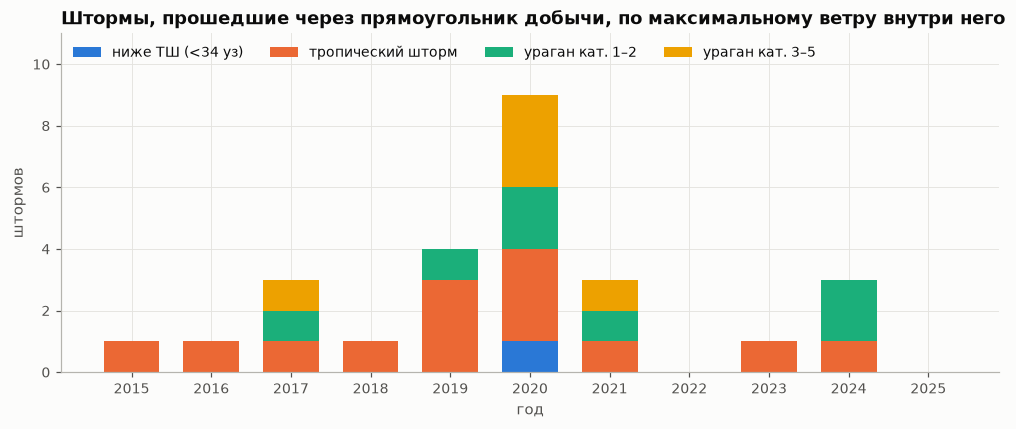

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
всего в сезоне,12,16,18,16,20,31,21,16,21,18,13
через прямоугольник,1,1,3,1,4,9,3,0,1,3,0
из них ураганов,0,0,2,0,1,5,2,0,0,2,0


In [14]:
ct = (
    storms.pivot_table(index="год", columns="класс", values="storm_id", aggfunc="count")
    .reindex(index=range(2015, 2026), columns=CLASSES)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(11, 4))
bottom = np.zeros(len(ct))
for i, cl in enumerate(CLASSES):
    ax.bar(ct.index, ct[cl], bottom=bottom, color=u.SERIES[i], label=cl, width=0.7)
    bottom += ct[cl].to_numpy()
ax.set_xticks(ct.index)
ax.set_ylabel("штормов")
ax.set_xlabel("год")
ax.set_title("Штормы, прошедшие через прямоугольник добычи, по максимальному ветру внутри него")
ax.legend(ncols=4, loc="upper left")
ax.set_ylim(0, bottom.max() + 2)
plt.show()
pd.DataFrame({"всего в сезоне": season, "через прямоугольник": ct.sum(axis=1).astype(int),
              "из них ураганов": (ct["ураган кат. 1–2"] + ct["ураган кат. 3–5"]).astype(int)}).T

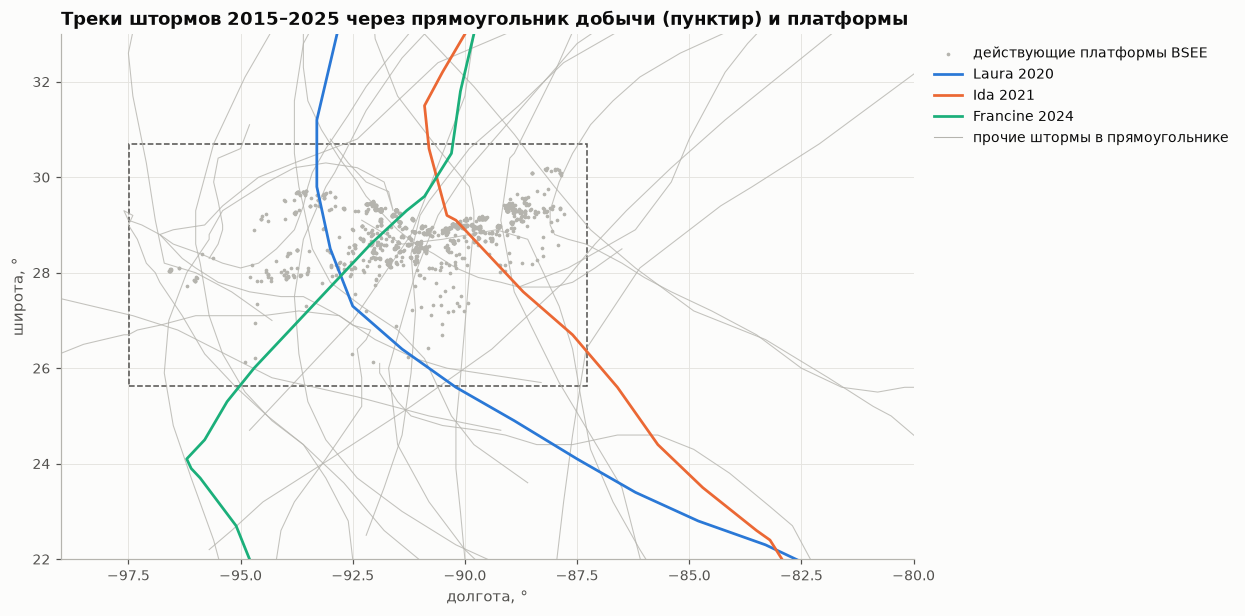

In [15]:
HIGHLIGHT = [("LAURA", 2020), ("IDA", 2021), ("FRANCINE", 2024)]
fig, ax = plt.subplots(figsize=(10, 6.2))
act = plat[plat["is_current"]]
ax.scatter(act["longitude"], act["latitude"], s=2, color=u.NEUTRAL, label="действующие платформы BSEE", zorder=1)
ax.add_patch(
    Rectangle((BOX["lon_min"], BOX["lat_min"]), BOX["lon_max"] - BOX["lon_min"], BOX["lat_max"] - BOX["lat_min"],
              fill=False, edgecolor=u.INK_MUTED, linestyle="--", linewidth=1, zorder=2)
)
hl_ids = [storms.loc[(storms["имя"] == n) & (storms["год"] == y), "storm_id"].iloc[0] for n, y in HIGHLIGHT]
for sid in storms["storm_id"]:
    if sid in hl_ids:
        continue
    t = hur[hur["storm_id"] == sid]
    ax.plot(t["longitude"], t["latitude"], color=u.NEUTRAL, linewidth=0.7, alpha=0.8, zorder=2)
for i, sid in enumerate(hl_ids):
    t = hur[hur["storm_id"] == sid]
    ax.plot(t["longitude"], t["latitude"], color=u.SERIES[i], linewidth=1.8, zorder=3,
            label=f"{t['storm_name'].iloc[0].title()} {t['year'].iloc[0]}")
ax.plot([], [], color=u.NEUTRAL, linewidth=0.7, label="прочие штормы в прямоугольнике")
ax.set_xlim(-99, -80)
ax.set_ylim(22, 33)
ax.set_xlabel("долгота, °")
ax.set_ylabel("широта, °")
ax.set_title("Треки штормов 2015–2025 через прямоугольник добычи (пунктир) и платформы")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

### 2.2 Влияние на месячную добычу

Отклонение — разница между добычей месяца и центрированной скользящей медианой за 13 месяцев.
Это описательная мера (использует будущие месяцы), не признак для модели.

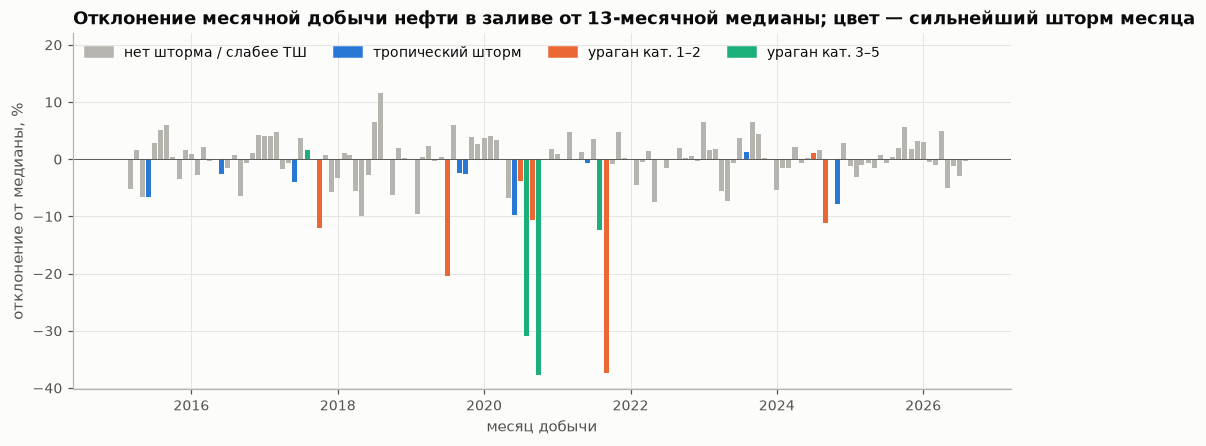

In [16]:
base = gm["oil_kbd"].rolling(13, center=True, min_periods=7).median()
gm["dev_kbd"] = gm["oil_kbd"] - base
gm["dev_pct"] = gm["dev_kbd"] / base * 100
gm["max_wind_box"] = ib.groupby("month")["max_wind_kt"].max().reindex(gm.index)
gm["storm_class"] = gm["max_wind_box"].map(lambda w: wind_class(w) if pd.notna(w) else "нет шторма")

fig, ax = plt.subplots(figsize=(11, 4.2))
xg = gm.index.to_timestamp()
cmap = {"нет шторма": u.NEUTRAL, "ниже ТШ (<34 уз)": u.NEUTRAL, "тропический шторм": u.SERIES[0],
        "ураган кат. 1–2": u.SERIES[1], "ураган кат. 3–5": u.SERIES[2]}
ax.bar(xg, gm["dev_pct"], width=25, color=gm["storm_class"].map(cmap))
handles = [Patch(color=cmap[lab], label=lab if lab != "нет шторма" else "нет шторма / слабее ТШ")
           for lab in ["нет шторма", "тропический шторм", "ураган кат. 1–2", "ураган кат. 3–5"]]
ax.axhline(0, color=u.INK_MUTED, linewidth=0.6)
ax.set_ylim(top=22)
ax.set_ylabel("отклонение от медианы, %")
ax.set_xlabel("месяц добычи")
ax.set_title("Отклонение месячной добычи нефти в заливе от 13-месячной медианы; цвет — сильнейший шторм месяца")
ax.legend(handles=handles, ncols=4, loc="upper left")
plt.show()

In [17]:
days = gm.index.days_in_month


def lost_mmbbl(p):
    """Недобор (только отрицательные отклонения), млн барр., за месяц p."""
    if p not in gm.index:
        return np.nan
    d = gm.loc[p, "dev_kbd"]
    return max(-d, 0) * p.days_in_month / 1e3


ev = storms[storms["ветер_макс_уз"] >= 34].copy()
ev["откл. месяц m, тыс. б/с"] = ev["month"].map(lambda p: gm["dev_kbd"].get(p, np.nan))
ev["откл. месяц m, %"] = ev["month"].map(lambda p: gm["dev_pct"].get(p, np.nan))
ev["откл. m+1, тыс. б/с"] = ev["month"].map(lambda p: gm["dev_kbd"].get(p + 1, np.nan))
ev["откл. m+1, %"] = ev["month"].map(lambda p: gm["dev_pct"].get(p + 1, np.nan))
ev["недобор m..m+1, млн барр."] = ev["month"].map(lambda p: lost_mmbbl(p) + lost_mmbbl(p + 1))
ev_tab = ev[["имя", "month", "класс", "ветер_макс_уз", "откл. месяц m, тыс. б/с", "откл. месяц m, %",
             "откл. m+1, тыс. б/с", "откл. m+1, %", "недобор m..m+1, млн барр."]].rename(columns={"month": "месяц m"})
ev_tab.round({c: 1 for c in ev_tab.select_dtypes("number").columns})

,имя,месяц m,класс,ветер_макс_уз,"откл. месяц m, тыс. б/с","откл. месяц m, %","откл. m+1, тыс. б/с","откл. m+1, %","недобор m..m+1, млн барр."
0,BILL,2015-06,тропический шторм,50,-101.1,-6.7,42.8,2.8,3.0
3,COLIN,2016-06,тропический шторм,45,-42.4,-2.7,-24.9,-1.6,2.0
4,CINDY,2017-06,тропический шторм,50,-66.8,-3.9,63.4,3.7,2.0
11,HARVEY,2017-08,ураган кат. 3–5,115,28.6,1.7,0.0,0.0,0.0
18,NATE,2017-10,ураган кат. 1–2,80,-203.8,-12.1,11.9,0.7,6.3
9,GORDON,2018-09,тропический шторм,60,0.0,0.0,-115.4,-6.2,3.6
1,BARRY,2019-07,ураган кат. 1–2,65,-394.2,-20.5,116.1,6.0,12.2
14,IMELDA,2019-09,тропический шторм,40,-47.6,-2.4,-49.5,-2.5,3.0
19,NESTOR,2019-10,тропический шторм,50,-49.5,-2.5,73.4,3.8,1.5
20,OLGA,2019-10,тропический шторм,45,-49.5,-2.5,73.4,3.8,1.5


In [18]:
by_class = gm.groupby("storm_class")["dev_pct"].agg(["size", "mean", "median", "min"]).round(2)
by_class.columns = ["месяцев", "среднее откл., %", "медиана, %", "минимум, %"]
by_class.reindex(["нет шторма", "ниже ТШ (<34 уз)", "тропический шторм", "ураган кат. 1–2", "ураган кат. 3–5"]).dropna(how="all")

,месяцев,"среднее откл., %","медиана, %","минимум, %"
storm_class,,,,
нет шторма,119.0,0.27,0.18,-9.86
тропический шторм,10.0,-3.50,-2.59,-9.70
ураган кат. 1–2,7.0,-13.48,-11.08,-37.37
ураган кат. 3–5,4.0,-19.83,-21.64,-37.72


### 2.3 Залив и национальная добыча EIA

`crude_production` в недельных данных EIA — тыс. барр./сут (оценка EIA для всей страны). Месячное значение —
среднее недель, чья пятница-конец недели попадает в месяц.

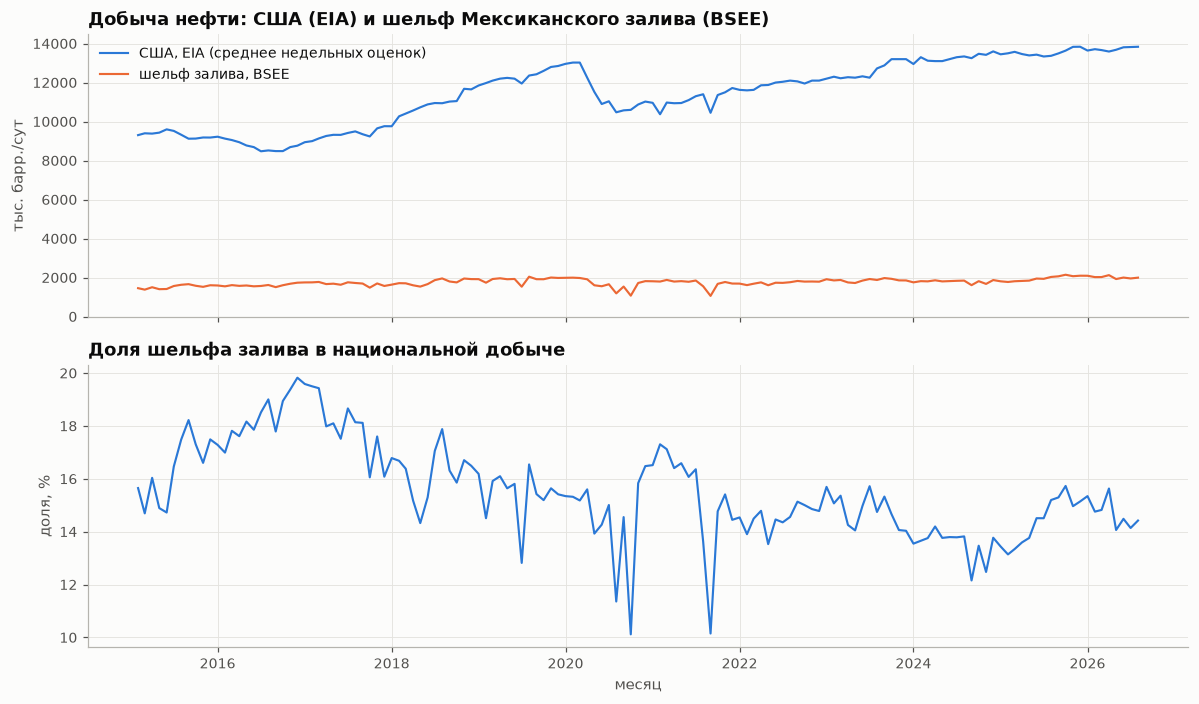

Доля недельных значений, кратных 100 тыс. б/с, по годам: {2015: 0.0, 2016: 0.0, 2017: 0.0, 2018: 0.6, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 0.87, 2025: 0.0, 2026: 0.0}
Значения кратны 100 с 2018-06-01 по 2024-11-08


,"залив, тыс. б/с","США, тыс. б/с","доля залива, %"
2015,1520.9,9324.8,16.3
2016,1600.3,8768.6,18.3
2017,1682.5,9323.7,18.1
2018,1759.0,10825.9,16.2
2019,1898.2,12295.8,15.4
2020,1669.1,11522.5,14.4
2021,1707.1,11085.8,15.4
2022,1731.6,11911.2,14.5
2023,1865.2,12585.0,14.8
2024,1792.5,13262.9,13.5


In [19]:
eia_w = eia[["period", "crude_production"]].dropna()
eia_m = eia_w.groupby(eia_w["period"].dt.to_period("M"))["crude_production"].mean()
cmp = pd.DataFrame({"gom_kbd": gm["oil_kbd"], "us_kbd": eia_m}).dropna()
cmp["share"] = cmp["gom_kbd"] / cmp["us_kbd"] * 100

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
xm = cmp.index.to_timestamp()
axes[0].plot(xm, cmp["us_kbd"], label="США, EIA (среднее недельных оценок)")
axes[0].plot(xm, cmp["gom_kbd"], label="шельф залива, BSEE")
axes[0].set_ylabel("тыс. барр./сут")
axes[0].set_ylim(bottom=0)
axes[0].set_title("Добыча нефти: США (EIA) и шельф Мексиканского залива (BSEE)")
axes[0].legend()
axes[1].plot(xm, cmp["share"], color=u.SERIES[0])
axes[1].set_ylabel("доля, %")
axes[1].set_title("Доля шельфа залива в национальной добыче")
axes[1].set_xlabel("месяц")
fig.tight_layout()
plt.show()

is_round = eia_w["crude_production"] % 100 == 0
round_share = is_round.groupby(eia_w["period"].dt.year).mean().round(2)
print("Доля недельных значений, кратных 100 тыс. б/с, по годам:", round_share.to_dict())
print(f"Значения кратны 100 с {eia_w.loc[is_round, 'period'].min().date()} по {eia_w.loc[is_round, 'period'].max().date()}")
cmp.groupby(cmp.index.year)[["gom_kbd", "us_kbd", "share"]].mean().round(1).rename(
    columns={"gom_kbd": "залив, тыс. б/с", "us_kbd": "США, тыс. б/с", "share": "доля залива, %"}
)

Ловит ли недельная оценка EIA ураганные остановки? Ниже — недельная добыча вокруг четырёх штормов
(неделя 0 — первая отчётная пятница не раньше входа шторма в прямоугольник), минус среднее четырёх предыдущих недель.

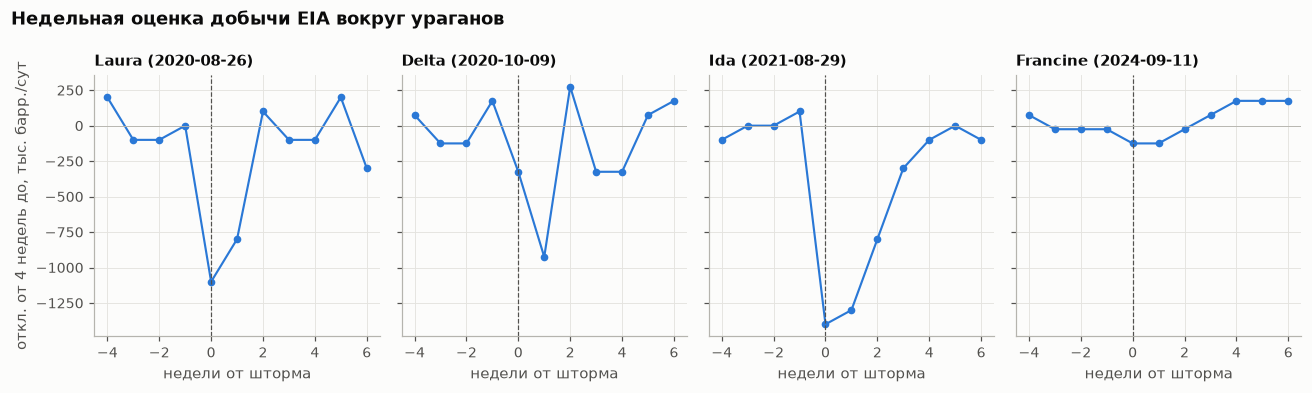

,шторм,"мин. откл. EIA, тыс. б/с","недобор EIA нед. 0..5, млн барр.","недобор BSEE m..m+1, млн барр."
0,Laura 2020,-1100.0,14.7,22.0
1,Delta 2020,-925.0,13.3,20.1
2,Ida 2021,-1400.0,27.3,25.8
3,Francine 2024,-125.0,1.9,6.0


In [20]:
EVENTS = [("LAURA", 2020), ("DELTA", 2020), ("IDA", 2021), ("FRANCINE", 2024)]
ew = eia_w.set_index("period")["crude_production"]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6), sharey=True)
weekly_rows = []
for ax, (name, yr) in zip(axes, EVENTS):
    row = storms[(storms["имя"] == name) & (storms["год"] == yr)].iloc[0]
    t0 = row["вход"].tz_convert(None).normalize()
    i0 = int(np.searchsorted(ew.index, t0))
    win = ew.iloc[i0 - 4 : i0 + 7]
    base_w = ew.iloc[i0 - 4 : i0].mean()
    rel = np.arange(-4, -4 + len(win))
    ax.plot(rel, win.to_numpy() - base_w, marker="o", color=u.SERIES[0])
    ax.axvline(0, color=u.INK_MUTED, linewidth=0.8, linestyle="--")
    ax.axhline(0, color=u.NEUTRAL, linewidth=0.6)
    ax.set_title(f"{name.title()} ({row['вход']:%Y-%m-%d})", fontsize=10)
    ax.set_xlabel("недели от шторма")
    loss_w = np.clip(base_w - ew.iloc[i0 : i0 + 6].to_numpy(), 0, None).sum() * 7 / 1e3
    weekly_rows.append(
        {"шторм": f"{name.title()} {yr}", "мин. откл. EIA, тыс. б/с": float((win - base_w).min()),
         "недобор EIA нед. 0..5, млн барр.": loss_w,
         "недобор BSEE m..m+1, млн барр.": lost_mmbbl(row["month"]) + lost_mmbbl(row["month"] + 1)}
    )
axes[0].set_ylabel("откл. от 4 недель до, тыс. барр./сут")
fig.suptitle("Недельная оценка добычи EIA вокруг ураганов", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()
pd.DataFrame(weekly_rows).round(1)

**Вывод.**
- Прямоугольник добычи — 25,63–30,69° с. ш., 97,48–87,28° з. д. (координаты есть у 1 733 из 1 734 добывавших
  сооружений). Из 202 штормов 2015–2025 через него прошли 26, из них 12 ураганов (5 — категории 3+: Harvey,
  Laura, Delta, Zeta, Ida). Распределение очень неравномерное: 9 штормов в 2020 г., ни одного в 2022 и 2025.
- Эффект на месячную добычу определяется силой шторма: без шторма среднее отклонение от медианы +0,27%,
  в месяцы с тропическим штормом −3,5%, с ураганом кат. 1–2 — −13,5%, кат. 3–5 — −19,8%. Худшие месяцы:
  2020-10 (Delta + Zeta) −37,7% (−650 тыс. б/с), 2021-09 (Ida) −37,4% (−633), 2020-08 (Laura + Marco) −30,9%,
  2019-07 (Barry) −20,5%, 2024-09 (Francine) −11,1% (−201). Harvey (2017-08) добычу почти не тронул (+1,7%):
  он ударил по побережью Техаса и НПЗ, а не по шельфу.
- Недобор по BSEE за месяцы m и m+1 — 26 млн барр. (Ida), 22 (Laura), 20 (Delta), 6 (Francine). Это величины
  того же порядка, что и недельные изменения запасов, которые мы прогнозируем. Недельная оценка EIA видит те же
  шоки: −1 400 тыс. б/с в неделю Ida (недобор за недели 0..5 — 27 млн барр. против 26 по BSEE), −1 100 у Laura,
  −925 у Delta (в окне Delta есть и Zeta), но только −125 у Francine.
- Доля шельфа залива в добыче США снизилась с 18,3% (2016) до 13,5% (2024); в 2025 г. — 14,4%. В месяцы ураганов
  она проваливается до ~10%. EIA округляла недельную добычу до 100 тыс. б/с с 2018-06-01 по 2024-11-08 — ступенчатость
  ряда зависит от периода.
- Последствия для недельной модели. (1) BSEE — месячные данные, публикуемые с задержкой: на 2026-11-04 сентябрь
  покрыт на ~30% строк, поэтому в бэктесте их можно использовать с лагом не меньше двух месяцев — только как
  медленный вес «важности» комплексов, а не как шок. (2) Остановка длится 1–3 недели, а месячное усреднение
  размазывает её на два месяца (Ida: −12% в августе и −37% в сентябре). (3) HURDAT2 — финальный best track:
  `point_in_time_safe = False` у всех 6 223 точек, есть 179 внесрочных точек (выход на сушу и т. п.), сезона 2026
  нет. Для недельного признака «шторм в прямоугольнике за неделю отчёта» best track — разумное приближение
  оперативных advisory по положению трека; интенсивность при пересмотре меняется сильнее (это знание предметной
  области, в этих данных не проверено). Оперативные advisory NHC за 2015–2026 стоит собрать отдельно. (4) Событий мало (12 ураганов за 11 лет), так что модель должна получать признак в простой форме
  (флаг или категория), без детальной параметризации.

## 3. Платформы

`bsee_platform_history` — одна строка на сооружение (`complex_id_num` + `structure_number`) с последней ревизией,
датами установки и демонтажа и координатами; `boem_platforms_current` — текущий слой карты BOEM.

In [21]:
inst = plat["install_date"].dt.year.value_counts().sort_index()
rem = plat["removal_date"].dt.year.value_counts().sort_index()
years = np.arange(1950, SNAPSHOT.year + 1)
active_ye = pd.Series(
    [
        int(((plat["install_date"] <= pd.Timestamp(f"{y}-12-31")) & (plat["removal_date"].isna() | (plat["removal_date"] > pd.Timestamp(f"{y}-12-31")))).sum())
        for y in years
    ],
    index=years,
)
qa_plat = {
    "сооружений": len(plat),
    "без даты установки": int(plat["install_date"].isna().sum()),
    "демонтировано": int(plat["removal_date"].notna().sum()),
    "действующих (is_current)": int(plat["is_current"].sum()),
    "демонтаж раньше установки": int((plat["removal_date"] < plat["install_date"]).sum()),
    "без координат": int((~plat["has_coordinates"]).sum()),
    "установка: min / max": f"{plat['install_date'].min():%Y-%m-%d} / {plat['install_date'].max():%Y-%m-%d}",
    "демонтаж: min / max": f"{plat['removal_date'].min():%Y-%m-%d} / {plat['removal_date'].max():%Y-%m-%d}",
}
pd.Series(qa_plat, name="значение").to_frame()

,значение
сооружений,7092
без даты установки,0
демонтировано,5791
действующих (is_current),1301
демонтаж раньше установки,0
без координат,8
установка: min / max,1942-01-01 / 2025-07-17
демонтаж: min / max,1973-12-31 / 2026-09-30


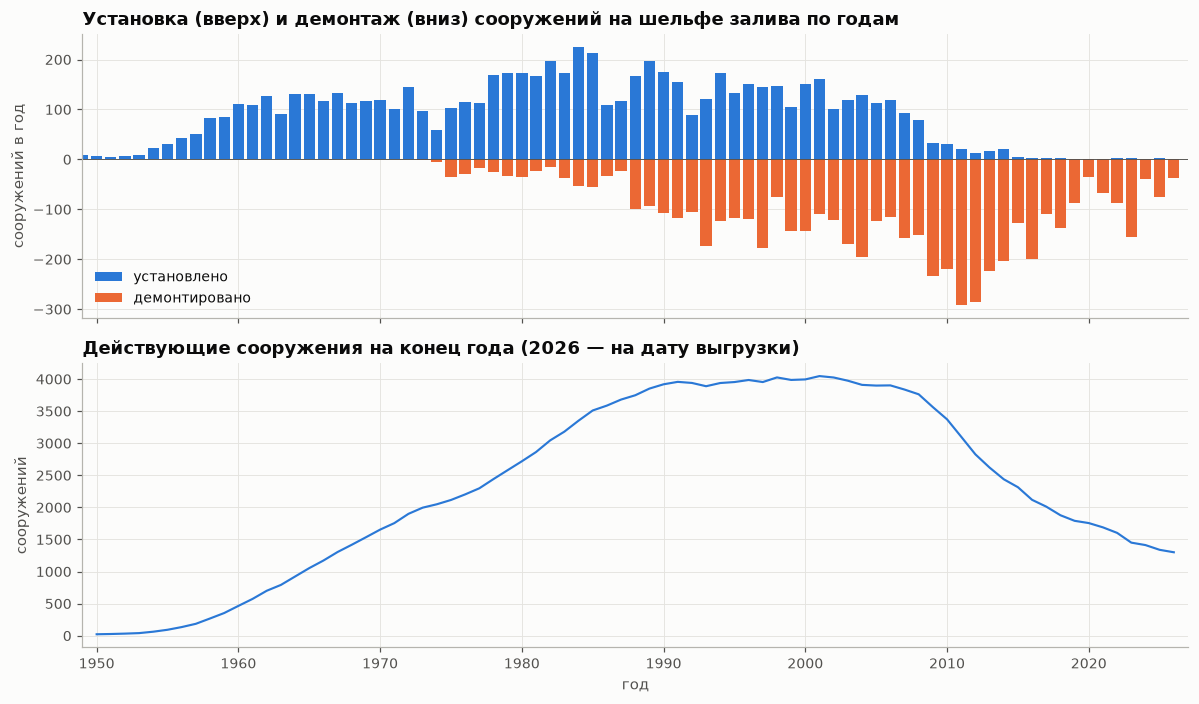

Действующих: на конец 2014 — 2439, на конец 2019 — 1791, на дату выгрузки — 1301; пик — 4047 в 2001


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
установлено,4,2,3,3,1,1,1,2,3,1,2,0
демонтировано,128,199,109,137,88,36,68,88,155,39,76,38


In [22]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
axes[0].bar(inst.index, inst.reindex(inst.index), color=u.SERIES[0], width=0.8, label="установлено")
axes[0].bar(rem.index, -rem, color=u.SERIES[1], width=0.8, label="демонтировано")
axes[0].axhline(0, color=u.INK_MUTED, linewidth=0.6)
axes[0].set_ylabel("сооружений в год")
axes[0].set_title("Установка (вверх) и демонтаж (вниз) сооружений на шельфе залива по годам")
axes[0].legend(loc="lower left")
axes[1].plot(active_ye.index, active_ye, color=u.SERIES[0])
axes[1].set_ylabel("сооружений")
axes[1].set_title(f"Действующие сооружения на конец года ({SNAPSHOT.year} — на дату выгрузки)")
axes[1].set_xlabel("год")
axes[1].set_xlim(1949, SNAPSHOT.year + 1)
fig.tight_layout()
plt.show()
print(f"Действующих: на конец 2014 — {active_ye[2014]}, на конец 2019 — {active_ye[2019]}, на дату выгрузки — {active_ye[SNAPSHOT.year]}; "
      f"пик — {active_ye.max()} в {active_ye.idxmax()}")
pd.DataFrame({"установлено": inst, "демонтировано": rem}).reindex(range(2015, SNAPSHOT.year + 1)).fillna(0).astype(int).T

In [23]:
type_tab = pd.DataFrame(
    {
        "всего": plat["structure_type_code"].value_counts(),
        "действующих": plat.loc[plat["is_current"], "structure_type_code"].value_counts(),
    }
).fillna(0).astype(int).sort_values("всего", ascending=False)
type_tab.head(10)

,всего,действующих
structure_type_code,,
FIXED,3796,980
CAIS,2584,261
WP,642,6
SEMI,21,17
SPAR,19,15
TLP,14,13
MOPU,5,2
MTLP,5,3
CT,3,2


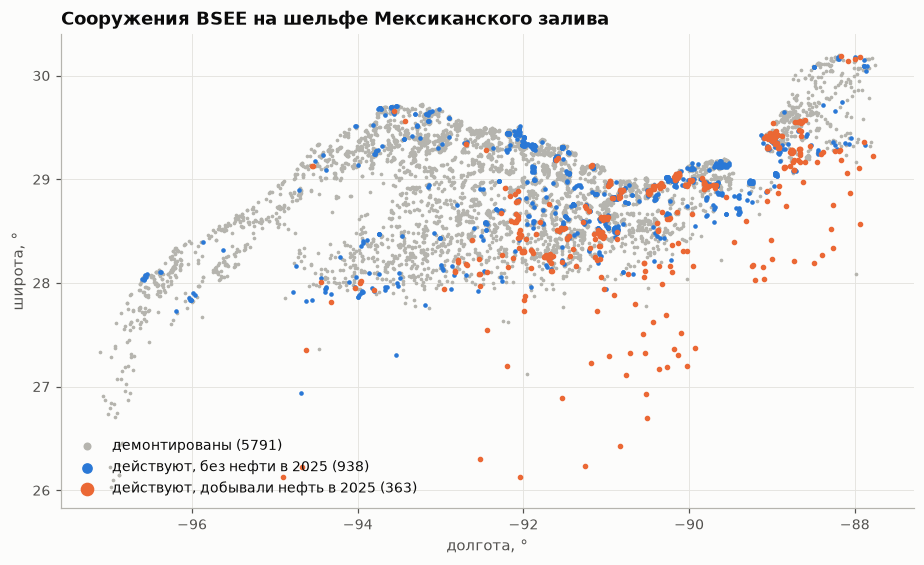

In [24]:
oil25 = gom[(gom["production_date"].dt.year == 2025)].groupby(["complex_id_num", "structure_number"])["bopd"].sum()
prod25_keys = set(oil25[oil25 > 0].index)
plat["prod_oil_2025"] = [k in prod25_keys for k in zip(plat["complex_id_num"], plat["structure_number"])]

fig, ax = plt.subplots(figsize=(10, 5.6))
removed = plat[~plat["is_current"]]
active_np = plat[plat["is_current"] & ~plat["prod_oil_2025"]]
active_p = plat[plat["is_current"] & plat["prod_oil_2025"]]
ax.scatter(removed["longitude"], removed["latitude"], s=2, color=u.NEUTRAL, label=f"демонтированы ({len(removed)})")
ax.scatter(active_np["longitude"], active_np["latitude"], s=4, color=u.SERIES[0], label=f"действуют, без нефти в 2025 ({len(active_np)})")
ax.scatter(active_p["longitude"], active_p["latitude"], s=7, color=u.SERIES[1], label=f"действуют, добывали нефть в 2025 ({len(active_p)})")
ax.set_xlabel("долгота, °")
ax.set_ylabel("широта, °")
ax.set_title("Сооружения BSEE на шельфе Мексиканского залива")
ax.legend(loc="lower left", markerscale=3)
plt.show()

In [25]:
bsee_current_c = set(plat.loc[plat["is_current"], "complex_id_num"].dropna().astype(int))
bsee_all_c = set(plat["complex_id_num"].dropna().astype(int))
boem_c = boem["COMPLEX_ID_NUM"].astype(int)
boem_cmp = {
    "точек в слое BOEM": len(boem),
    "из них с REMOVAL_DATE": int(boem["REMOVAL_DATE"].notna().sum()),
    "к западу от 100° з. д. (Тихий океан)": int((boem["longitude"] < -100).sum()),
    "комплексов BOEM": int(boem_c.nunique()),
    "комплексов BOEM, действующих в BSEE": int(boem_c[boem_c.isin(bsee_current_c)].nunique()),
    "комплексов BOEM, в BSEE только демонтированные": int(boem_c[boem_c.isin(bsee_all_c - bsee_current_c)].nunique()),
    "комплексов BOEM, нет в BSEE": int(boem_c[~boem_c.isin(bsee_all_c)].nunique()),
    "действующих комплексов BSEE": len(bsee_current_c),
}
pd.Series(boem_cmp, name="значение").to_frame()

,значение
точек в слое BOEM,1315
из них с REMOVAL_DATE,0
к западу от 100° з. д. (Тихий океан),23
комплексов BOEM,1075
"комплексов BOEM, действующих в BSEE",1052
"комплексов BOEM, в BSEE только демонтированные",0
"комплексов BOEM, нет в BSEE",23
действующих комплексов BSEE,1061


**Вывод.**
- В `bsee_platform_history` 7 092 сооружения: 5 791 демонтировано, 1 301 действует. Дата установки есть у всех,
  координат нет у 8, демонтажей раньше установки нет. Последний демонтаж датирован 2026-09-30.
- Шельф быстро выводится из эксплуатации: пик — 4 047 действующих сооружений в 2001 г., 2 439 на конец 2014-го,
  1 791 на конец 2019-го и 1 301 сейчас (−47% к 2014). За 2015–2026 установлено всего 23 сооружения, а демонтировано
  1 161 (36–199 в год). Среди действующих 980 FIXED и 261 кессон, плавучих хабов (SPAR 15, TLP 13, SEMI 17, FPSO 2)
  немного, но именно они дают основную нефть.
- Нефть в 2025 г. давали только 363 из 1 301 действующего сооружения — для экспозиции к ураганам нужна выборка
  «действует и добывает», а не «не демонтировано».
- Слой BOEM содержит только текущие объекты: 1 315 точек, `REMOVAL_DATE` пуст у всех, 23 точки — Тихий океан.
  1 052 из 1 075 комплексов BOEM действуют и в BSEE, остальные 23 — тихоокеанские, которых в BSEE-истории нет.
  Как исторический источник для бэктеста годится только BSEE.

## 4. Офшорные трубопроводы BSEE

`seg_length` — длина сегмента в футах (как в BSEE Pipeline Masters; переводим в км ×0,0003048).
«Нефтяные» сегменты — `prod_code` из `CRUDE_OIL_PRODUCT_CODES` (BLKO, BLOH, G/O, G/OH, O/W, OIL, OILH).

In [26]:
FT_KM = 0.0003048
pipes["len_km"] = pd.to_numeric(pipes["seg_length"], errors="coerce") * FT_KM
pipes["status_label"] = pipes["status_label"].fillna("(нет в справочнике)")
st = pipes.groupby(["status_code", "status_label"], dropna=False).agg(
    сегментов=("segment_num", "size"),
    нефтяных=("is_crude_oil_related", "sum"),
    длина_км=("len_km", "sum"),
    с_геометрией=("geometry_json", lambda s: s.notna().mean() * 100),
)
st["доля нефтяных, %"] = st["нефтяных"] / st["сегментов"] * 100
st = st.sort_values("сегментов", ascending=False)
print(f"Сегментов: {len(pipes)}, нефтяных: {int(pipes['is_crude_oil_related'].sum())} "
      f"({pipes['is_crude_oil_related'].mean() * 100:.1f}%); файл нефтяных: {len(pipes_crude)} строк")
print(f"Дубликатов segment_num: {int(pipes['segment_num'].duplicated().sum())}; доля с геометрией BOEM: {pipes['geometry_json'].notna().mean() * 100:.1f}%")
st.round(1)

Сегментов: 21314, нефтяных: 7030 (33.0%); файл нефтяных: 7030 строк
Дубликатов segment_num: 0; доля с геометрией BOEM: 81.4%


,,сегментов,нефтяных,длина_км,с_геометрией,"доля нефтяных, %"
status_code,status_label,,,,,
ABN,abandoned,10251,2339,39595.5,97.7,22.8
ACT,active,3932,1972,28285.3,97.1,50.2
CNCL,cancelled,1966,531,7392.4,0.1,27.0
OUT,out_of_service,1479,787,3852.5,97.4,53.2
REM,removed,1332,505,1553.1,94.5,37.9
COMB,combined,1116,381,1787.6,0.1,34.1
PABN,proposed_abandonment,523,201,2741.9,94.3,38.4
PROP,proposed,361,179,2083.7,6.4,49.6
A/C,abandoned_and_combined,187,67,276.7,98.9,35.8


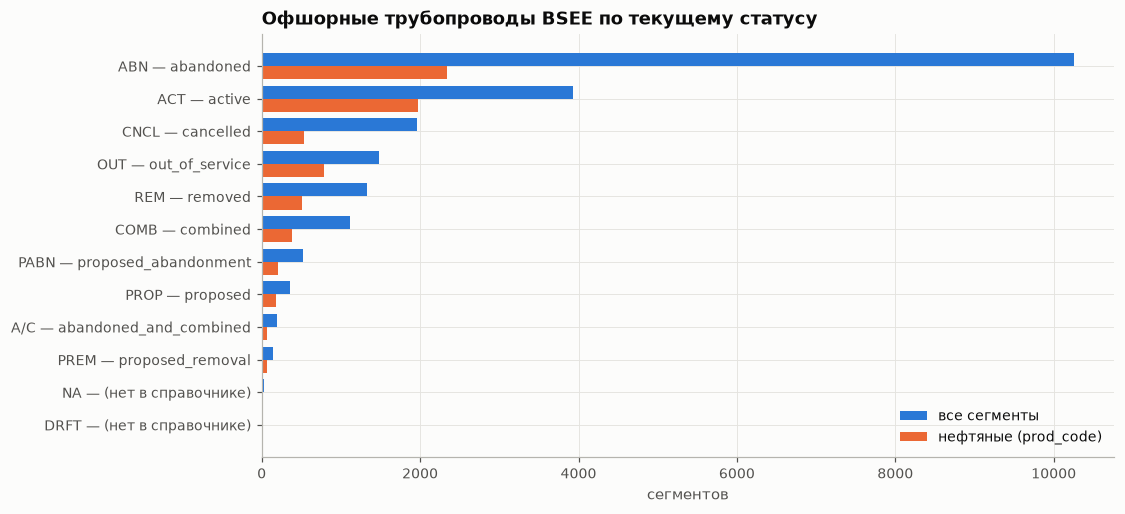

In [27]:
st_plot = st.reset_index()
st_plot["метка"] = st_plot["status_code"].fillna("NA") + " — " + st_plot["status_label"]
st_plot = st_plot.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5))
yy = np.arange(len(st_plot))
ax.barh(yy + 0.2, st_plot["сегментов"], height=0.4, color=u.SERIES[0], label="все сегменты")
ax.barh(yy - 0.2, st_plot["нефтяных"], height=0.4, color=u.SERIES[1], label="нефтяные (prod_code)")
ax.set_yticks(yy)
ax.set_yticklabels(st_plot["метка"])
ax.set_xlabel("сегментов")
ax.set_title("Офшорные трубопроводы BSEE по текущему статусу")
ax.legend(loc="lower right")
plt.show()

In [28]:
L = pipes["len_km"]
len_qa = {
    "без длины": int(L.isna().sum()),
    "нулевая длина": int((L == 0).sum()),
    "медиана, км": round(float(L[L > 0].median()), 2),
    "95-й перцентиль, км": round(float(L[L > 0].quantile(0.95)), 1),
    "сумма всех, км": round(float(L.sum()), 0),
    "сумма действующих (ACT), км": round(float(L[pipes["status_code"].eq("ACT")].sum()), 0),
    "сумма действующих нефтяных, км": round(float(L[pipes["status_code"].eq("ACT") & pipes["is_crude_oil_related"]].sum()), 0),
    "сегментов длиннее 300 км": int((L > 300).sum()),
    "действующих короче 50 м": int((pipes["status_code"].eq("ACT") & L.between(1e-9, 0.05)).sum()),
    "  из них BLKO, %": round(float(pipes.loc[pipes["status_code"].eq("ACT") & L.between(1e-9, 0.05), "prod_code"].eq("BLKO").mean() * 100), 1),
}
display(pd.Series(len_qa, name="значение").to_frame())
pipes.nlargest(6, "len_km")[["segment_num", "len_km", "orig_id_name", "dest_id_name", "status_code", "prod_code"]].round(1)

,значение
без длины,2236.00
нулевая длина,1007.00
"медиана, км",1.65
"95-й перцентиль, км",18.90
"сумма всех, км",87941.00
"сумма действующих (ACT), км",28285.00
"сумма действующих нефтяных, км",10986.00
сегментов длиннее 300 км,3.00
действующих короче 50 м,892.00
"из них BLKO, %",78.70


,segment_num,len_km,orig_id_name,dest_id_name,status_code,prod_code
15580,17364,1663.7,STATE,STATE,ACT,CBLC
11327,12373,609.2,F/S,F/S,ACT,GAS
16913,18711,336.7,PLEM,Platform J,ACT,GAS
15158,16327,246.4,A-Jack St. Malo,Platform A,ACT,GAS
16811,18606,233.6,PLET,Platform A,ACT,OIL
19412,21515,225.5,Kaskida FPU,A (Boxer),PROP,BLKO


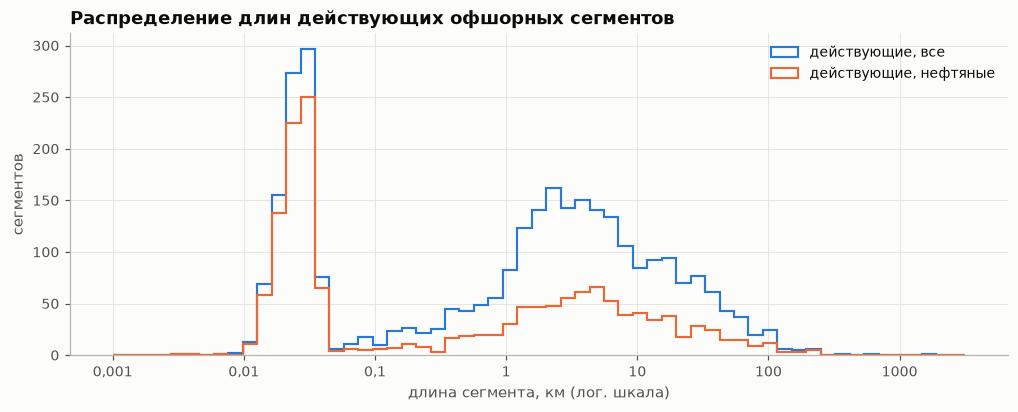

In [29]:
fig, ax = plt.subplots(figsize=(11, 3.8))
bins = np.linspace(-3, 3.5, 60)
act_p = pipes[pipes["status_code"].eq("ACT") & (pipes["len_km"] > 0)]
ax.hist(np.log10(act_p["len_km"]), bins=bins, histtype="step", linewidth=1.4, color=u.SERIES[0], label="действующие, все")
ax.hist(np.log10(act_p.loc[act_p["is_crude_oil_related"], "len_km"]), bins=bins, histtype="step", linewidth=1.4, color=u.SERIES[1], label="действующие, нефтяные")
ax.set_xticks(range(-3, 4))
ax.set_xticklabels(["0,001", "0,01", "0,1", "1", "10", "100", "1000"])
ax.set_xlabel("длина сегмента, км (лог. шкала)")
ax.set_ylabel("сегментов")
ax.set_title("Распределение длин действующих офшорных сегментов")
ax.legend()
plt.show()

### 4.1 Недопустимые даты

Нижняя граница правдоподобия — самая ранняя установка сооружения в BSEE (1942 г.), верхняя — дата выгрузки.

In [30]:
LOW = plat["install_date"].min()
DATE_COLS = ["aban_aprv_dt", "aban_date", "approved_date", "ppl_const_date", "last_rev_date", "init_hs_dt", "prpsl_con_dt"]


def date_qa(df, cols, name):
    out = []
    for c in cols:
        s = df[c]
        out.append(
            {
                "таблица": name, "колонка": c, "заполнено": int(s.notna().sum()),
                "min": s.min(), "max": s.max(),
                f"< {LOW.year}": int((s < LOW).sum()), "> выгрузки": int((s > SNAPSHOT).sum()),
            }
        )
    return out


dq = pd.DataFrame(
    date_qa(pipes, DATE_COLS, "offshore_pipelines")
    + date_qa(pipes_crude, DATE_COLS, "offshore_crude_pipelines")
    + date_qa(pev, ["history_date", "last_rev_date"], "pipeline_history_events")
)
dq["min"] = dq["min"].astype(str).str[:10]
dq["max"] = dq["max"].astype(str).str[:10]
dq

,таблица,колонка,заполнено,min,max,< 1942,> выгрузки
0,offshore_pipelines,aban_aprv_dt,10317,1970-01-01,2026-10-27,0,0
1,offshore_pipelines,aban_date,9953,1870-03-01,2026-10-15,10,0
2,offshore_pipelines,approved_date,15904,1948-09-10,2026-10-29,0,0
3,offshore_pipelines,ppl_const_date,2111,1903-04-23,2019-11-06,1,0
4,offshore_pipelines,last_rev_date,20690,1992-11-02,2026-10-30,0,0
5,offshore_pipelines,init_hs_dt,12262,1952-08-23,2019-09-27,0,0
6,offshore_pipelines,prpsl_con_dt,0,NaN,NaN,0,0
7,offshore_crude_pipelines,aban_aprv_dt,2557,1970-01-01,2026-10-27,0,0
8,offshore_crude_pipelines,aban_date,2426,1870-03-01,2026-10-05,3,0
9,offshore_crude_pipelines,approved_date,4919,1948-09-10,2026-10-29,0,0


In [31]:
logic = {
    "aban_date < approved_date": int((pipes["aban_date"] < pipes["approved_date"]).sum()),
    "aban_date < ppl_const_date": int((pipes["aban_date"] < pipes["ppl_const_date"]).sum()),
    "ppl_const_date < approved_date": int((pipes["ppl_const_date"] < pipes["approved_date"]).sum()),
    "aban_aprv_dt > aban_date + 5 лет": int((pipes["aban_aprv_dt"] > pipes["aban_date"] + pd.DateOffset(years=5)).sum()),
}
display(pd.Series(logic, name="сегментов (все)").to_frame())
bad_rows = []
for c in DATE_COLS:
    m = (pipes[c] < LOW) | (pipes[c] > SNAPSHOT)
    for _, r in pipes.loc[m].iterrows():
        bad_rows.append({"segment_num": r["segment_num"], "колонка": c, "значение": str(r[c])[:10],
                         "approved_date": str(r["approved_date"])[:10], "status_code": r["status_code"],
                         "нефтяной": bool(r["is_crude_oil_related"])})
pd.DataFrame(bad_rows)

,сегментов (все)
aban_date < approved_date,29
aban_date < ppl_const_date,8
ppl_const_date < approved_date,152
aban_aprv_dt > aban_date + 5 лет,189


,segment_num,колонка,значение,approved_date,status_code,нефтяной
0,500090,aban_date,1870-03-01,NaT,ABN,False
1,500147,aban_date,1870-03-01,NaT,ABN,False
2,500200,aban_date,1870-03-01,NaT,ABN,True
3,500365,aban_date,1870-03-01,NaT,ABN,True
4,500467,aban_date,1870-03-01,NaT,ABN,False
5,500476,aban_date,1870-03-01,NaT,ABN,False
6,500606,aban_date,1870-03-01,NaT,ABN,False
7,500661,aban_date,1870-03-01,NaT,ABN,True
8,500663,aban_date,1870-03-01,NaT,ABN,False
9,501198,aban_date,1870-03-01,NaT,ABN,False


In [32]:
bad_ev = pev[(pev["history_date"] < LOW) | (pev["history_date"] > SNAPSHOT)].copy()
bad_ev["history_date"] = bad_ev["history_date"].astype(str).str[:10]
bad_ev["remark"] = bad_ev["remark"].str[:70]
bad_ev[["segment_num", "history_date", "history_code", "last_rev_date", "remark"]]

,segment_num,history_date,history_code,last_rev_date,remark
32882,10376,0020-11-09,B,NaT,Partial decommissioning application approved (...
37278,11167,7001-07-02,E,2001-07-05,P/L cancelled as per letted dated 07/02/2001.
43774,12374,0199-11-19,<NA>,1999-11-19,Originates at VR 14 Well #2 in state waters.
76364,19050,0018-04-15,E,2020-04-28,ROW expired on 4/15/2018 because no COO requ...
76550,19096,0020-12-18,E,NaT,Notification of FLET movement
80201,20183,0019-09-20,A,NaT,Installation of the subject umbilical complete...
80594,20343,0020-07-24,E,NaT,Pipeline installation operations completed 07/...
80822,20465,0020-09-02,P,NaT,Pipeline installation submittal approved.
81280,20532,0020-09-02,P,NaT,Pipeline installation submittal approved.


### 4.2 События истории трубопроводов

In [33]:
ev_codes = pev["history_code"].fillna("(пусто)")
code_tab = pd.DataFrame(
    {"событий": ev_codes.value_counts(), "в справочнике BSEE": ev_codes.value_counts().index.isin(list(set(pev.loc[pev["history_code_documented"], "history_code"])))}
)
print(f"Событий: {len(pev)}; с кодом из справочника: {int(pev['history_code_documented'].sum())}; "
      f"пустой код: {int(pev['history_code'].isna().sum())}; код вне справочника: {int((pev['history_code'].notna() & ~pev['history_code_documented']).sum())}")
print("Сегментов событий, найденных в мастер-таблице:", f"{pev['segment_num'].isin(pipes['segment_num']).mean() * 100:.1f}%;",
      "сегментов мастер-таблицы с событиями:", f"{pipes['segment_num'].isin(pev['segment_num']).mean() * 100:.1f}%")
code_tab.T

Событий: 85139; с кодом из справочника: 71788; пустой код: 12572; код вне справочника: 779
Сегментов событий, найденных в мастер-таблице: 100.0%; сегментов мастер-таблицы с событиями: 76.5%


history_code,E,(пусто),O,B,L,D,S,U,T,C,R,M,P,A,G,F,N,V,I,H,J,W,K,Q,Z,X,0
событий,17280,12572,12541,11564,6522,4714,4697,3449,3193,1819,1550,1459,1387,1217,375,319,205,82,44,33,26,24,24,19,16,7,1
в справочнике BSEE,True,False,True,True,True,True,True,True,True,True,True,True,True,True,False,True,False,False,True,True,False,False,False,False,False,False,False


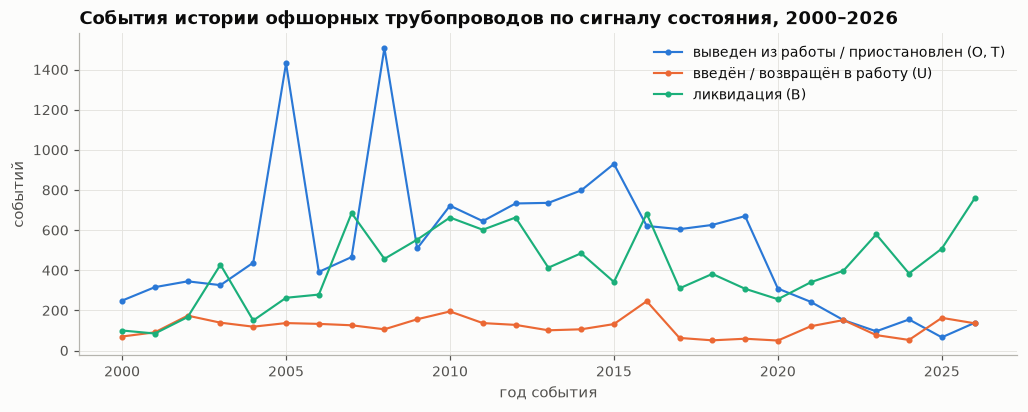

События O/T в месяц, 2015+: среднее 32.8 | в месяцы урагана в прямоугольнике: 39.8 | в следующие за ними месяцы: 36.2


In [34]:
pev_ok = pev[(pev["history_date"] >= pd.Timestamp("2000-01-01")) & (pev["history_date"] <= SNAPSHOT)]
sig = pev_ok.groupby([pev_ok["history_date"].dt.year, pev_ok["service_state_signal"].fillna("прочие")]).size().unstack(fill_value=0)
SIG = [("inactive", "выведен из работы / приостановлен (O, T)"), ("active", "введён / возвращён в работу (U)"),
       ("abandonment_related", "ликвидация (B)")]
fig, ax = plt.subplots(figsize=(11, 3.8))
for i, (k, lab) in enumerate(SIG):
    ax.plot(sig.index, sig[k], marker="o", markersize=3, color=u.SERIES[i], label=lab)
ax.set_xlabel("год события")
ax.set_ylabel("событий")
ax.set_title("События истории офшорных трубопроводов по сигналу состояния, 2000–2026")
ax.legend()
plt.show()

pev_m = pev_ok[pev_ok["history_date"] >= pd.Timestamp("2015-01-01")]
o_m = pev_m[pev_m["history_code"].isin(["O", "T"])].groupby(pev_m["history_date"].dt.to_period("M")).size()
o_m = o_m.reindex(pd.period_range("2015-01", LAST_FULL, freq="M"), fill_value=0)
hur_months = set(storms.loc[storms["ветер_макс_уз"] >= 64, "month"])
print("События O/T в месяц, 2015+: среднее", round(o_m.mean(), 1),
      "| в месяцы урагана в прямоугольнике:", round(o_m[o_m.index.isin(hur_months)].mean(), 1),
      "| в следующие за ними месяцы:", round(o_m[o_m.index.isin({p + 1 for p in hur_months})].mean(), 1))

**Вывод.**
- 21 314 сегментов, `segment_num` уникален. Нефтяных — 7 030 (33,0%), среди действующих (3 932) — 50,2%.
  По статусам: ABN 10 251, ACT 3 932, CNCL 1 966, OUT 1 479, REM 1 332, COMB 1 116; 23 сегмента без статуса и
  1 со статусом `DRFT`, которого нет в справочнике. Геометрия BOEM есть у 81,4% сегментов (у действующих —
  97,1%), у CNCL и COMB её почти нет (0,1%).
- Длины: 2 236 сегментов без длины, 1 007 с нулевой длиной, медиана 1,65 км, сумма по действующим — 28 285 км
  (из них нефтяных 10 986). 892 действующих сегмента короче 50 м (78,7% из них BLKO — по-видимому, линии внутри
  платформы). Явные выбросы — сегмент 17364 (CBLC, STATE→STATE) длиной 1 664 км и 12373 (GAS) длиной 609 км.
- Даты: `aban_date` = 1870-03-01 у 10 сегментов (все ABN, у всех пустой `approved_date`, номера 500090–501198,
  3 из них нефтяные; файл нефтяных затронут тремя строками). `ppl_const_date` = 1903-04-23 у сегмента 9854
  (одобрен в 1993). `prpsl_con_dt` пуст полностью. Логических противоречий больше: `aban_date < approved_date` —
  29, `aban_date < ppl_const_date` — 8, `ppl_const_date < approved_date` — 152.
- `history_date` от 0018-04-15 до 7001-07-02: 9 событий вне диапазона [1942, выгрузка]. По примечаниям это
  опечатки в годе: 0018/0019/0020 → 2018–2020, 0199 → 1999, 7001 → 2001 (в `remark` — «07/02/2001»).
  Из 85 139 событий у 12 572 пустой код и у 779 — код вне справочника (G, N, V, J, W, K, Q, Z, X, 0).
  Все события ссылаются на существующие сегменты; события есть у 76,5% сегментов.
- События O/T («выведен из работы / приостановлен») резко подскакивали в 2005 и 2008 гг. (видимо, последствия
  Katrina/Rita и Gustav/Ike). После 2015 г. связь с ураганами слабая: в среднем 32,8 события в месяц против 39,8
  в месяцы ураганов. Это регуляторные записи, которые вносятся с задержкой, — как недельный шок они не подходят.

## 5. Мощности НПЗ (EIA Refinery Capacity)

Одна строка — НПЗ×год отчёта; `total_operable_capacity_bpcd` — действующая (operable) мощность первичной
перегонки, барр./календарные сутки, на 1 января `report_year`; `operating_capacity_bpcd` — работающая часть;
`idle_capacity_bpcd` — разность. Территории (PADD 6) лежат в отдельном файле.

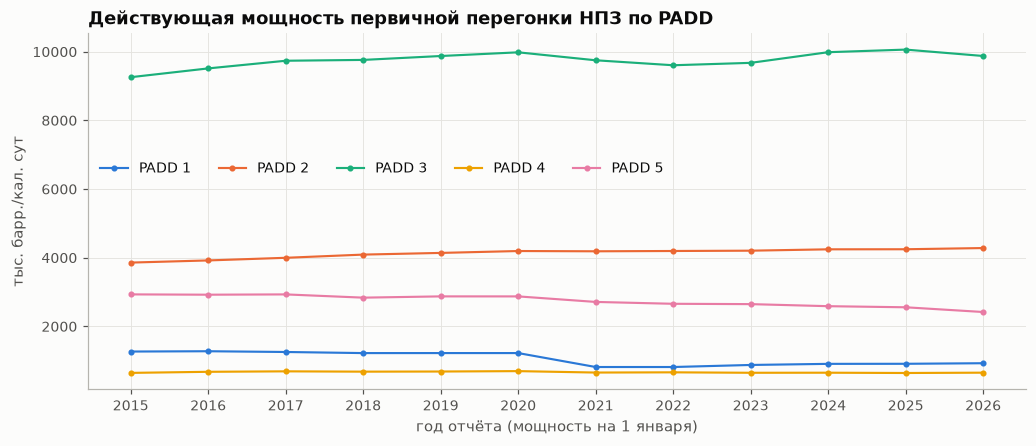

,PADD 1,PADD 2,PADD 3,PADD 4,PADD 5,США
report_year,,,,,,
2015,1268.0,3859.0,9259.0,647.0,2933.0,17967.0
2016,1278.0,3922.0,9515.0,679.0,2924.0,18317.0
2017,1256.0,3999.0,9738.0,692.0,2933.0,18617.0
2018,1224.0,4092.0,9762.0,683.0,2838.0,18598.0
2019,1224.0,4141.0,9876.0,687.0,2875.0,18802.0
2020,1224.0,4196.0,9983.0,698.0,2875.0,18976.0
2021,818.0,4188.0,9751.0,657.0,2714.0,18128.0
2022,818.0,4197.0,9607.0,663.0,2659.0,17944.0
2023,878.0,4206.0,9677.0,650.0,2650.0,18060.0


In [35]:
padd_cap = ref.pivot_table(index="report_year", columns="padd", values="total_operable_capacity_bpcd", aggfunc="sum") / 1e3
padd_cap.columns = [f"PADD {c}" for c in padd_cap.columns]
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, c in enumerate(padd_cap.columns):
    ax.plot(padd_cap.index, padd_cap[c], marker="o", markersize=3, color=u.SERIES[i], label=c)
ax.set_xticks(padd_cap.index)
ax.set_ylabel("тыс. барр./кал. сут")
ax.set_xlabel("год отчёта (мощность на 1 января)")
ax.set_title("Действующая мощность первичной перегонки НПЗ по PADD")
ax.legend(ncols=5, loc="center left", bbox_to_anchor=(0, 0.62))
plt.show()
padd_cap.assign(**{"США": padd_cap.sum(axis=1)}).round(0)

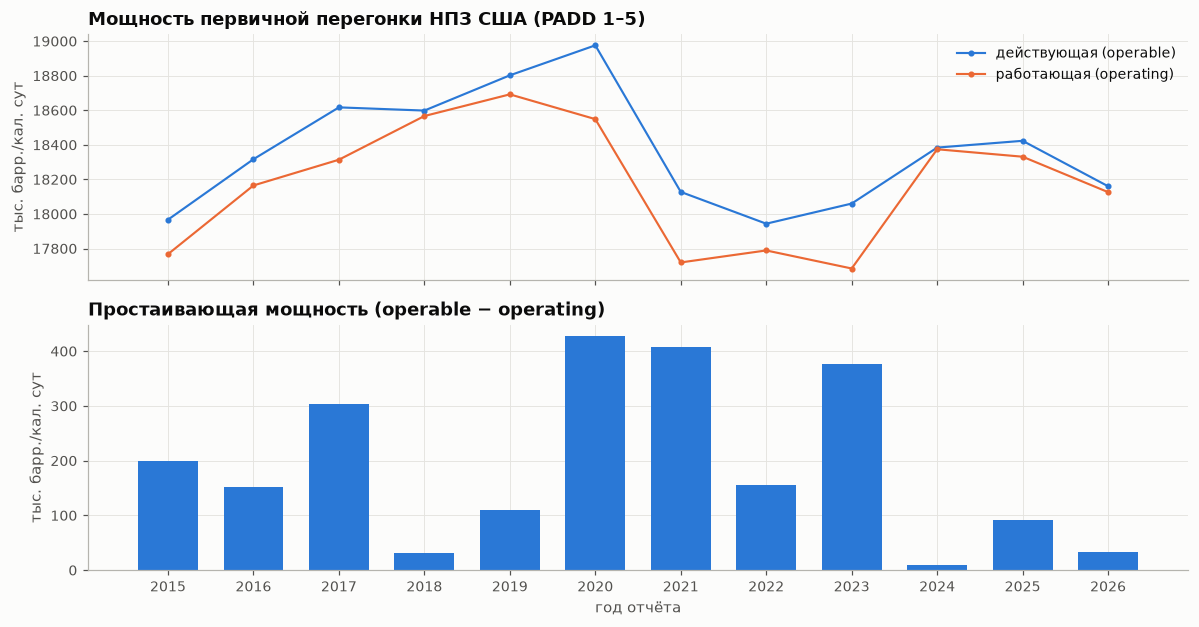

,НПЗ,operable,operating,idle,простаивающих_НПЗ,operating_импутирован_0,"idle, %"
report_year,,,,,,,
2015,135,17967.1,17767.6,199.5,3,3,1.1
2016,137,18317.0,18165.1,151.9,2,2,0.8
2017,137,18617.0,18314.1,302.9,4,4,1.6
2018,132,18598.5,18566.9,31.6,0,0,0.2
2019,132,18802.4,18692.3,110.1,3,3,0.6
2020,132,18976.1,18549.0,427.1,4,4,2.3
2021,126,18127.7,17719.6,408.1,5,5,2.3
2022,127,17943.8,17789.0,154.8,5,5,0.9
2023,126,18060.4,17684.5,375.8,5,5,2.1


In [36]:
yr = ref.groupby("report_year").agg(
    НПЗ=("refinery_key", "size"),
    operable=("total_operable_capacity_bpcd", "sum"),
    operating=("operating_capacity_bpcd", "sum"),
    idle=("idle_capacity_bpcd", "sum"),
    простаивающих_НПЗ=("is_idle", "sum"),
    operating_импутирован_0=("operating_capacity_imputed_zero", "sum"),
)
for c in ["operable", "operating", "idle"]:
    yr[c] = yr[c] / 1e3
yr["idle, %"] = yr["idle"] / yr["operable"] * 100

fig, axes = plt.subplots(2, 1, figsize=(11, 5.8), sharex=True)
axes[0].plot(yr.index, yr["operable"], marker="o", markersize=3, label="действующая (operable)")
axes[0].plot(yr.index, yr["operating"], marker="o", markersize=3, label="работающая (operating)")
axes[0].set_ylabel("тыс. барр./кал. сут")
axes[0].set_title("Мощность первичной перегонки НПЗ США (PADD 1–5)")
axes[0].legend()
axes[1].bar(yr.index, yr["idle"], color=u.SERIES[0], width=0.7)
axes[1].set_ylabel("тыс. барр./кал. сут")
axes[1].set_title("Простаивающая мощность (operable − operating)")
axes[1].set_xticks(yr.index)
axes[1].set_xlabel("год отчёта")
fig.tight_layout()
plt.show()
yr.round(1)

### 5.1 Закрытия и конверсии 2019–2026

`refinery_key` включает название компании и корпорации, поэтому меняется при каждой смене владельца, а
`refinery_location_key` (штат|город) — при смене написания города. Для поиска закрытий нормализуем площадку:
нижний регистр, без пробелов и суффиксов « east»/« west», и ищем годовые падения мощности площадки ≥ 20 тыс. б/с.

In [37]:
key_span = ref.groupby("refinery_key")["report_year"].nunique()
print(f"refinery_key: {ref['refinery_key'].nunique()} уникальных при {ref.groupby('report_year').size().mean():.0f} НПЗ в год; "
      f"во всех {ref['report_year'].nunique()} годах — {int((key_span == ref['report_year'].nunique()).sum())}")
print(f"refinery_location_key: {ref['refinery_location_key'].nunique()} уникальных; "
      f"пар (год, location_key) с несколькими НПЗ: {int(ref.duplicated(['report_year', 'refinery_location_key'], keep=False).sum())} строк")

ref["site_norm"] = (
    ref["state_name"].str.lower() + "|"
    + ref["site"].str.lower().str.replace(r"\s+(east|west)$", "", regex=True).str.replace(" ", "", regex=False)
)
site_y = ref.groupby(["site_norm", "report_year"]).agg(
    cap=("total_operable_capacity_bpcd", "sum"), op=("operating_capacity_bpcd", "sum"),
    companies=("company_name", lambda s: "; ".join(sorted(set(s)))),
)
cap_w = site_y["cap"].unstack().fillna(0)
drops = []
for y in range(2020, int(ref["report_year"].max()) + 1):
    d = cap_w[y] - cap_w[y - 1]
    for site in d[d <= -20000].index:
        before = site_y.loc[(site, y - 1), "companies"]
        after = site_y.loc[(site, y), "companies"] if (site, y) in site_y.index else "—"
        drops.append({"площадка": site, "год отчёта": y, "мощность до, тыс.": cap_w.loc[site, y - 1] / 1e3,
                      "после, тыс.": cap_w.loc[site, y] / 1e3, "компании до": before[:60], "компании после": after[:60]})
drops = pd.DataFrame(drops)
print("Суммарное снижение мощности по этим событиям, тыс. б/с:", round((drops["мощность до, тыс."] - drops["после, тыс."]).sum(), 0))
drops.round(1)

refinery_key: 239 уникальных при 130 НПЗ в год; во всех 12 годах — 63
refinery_location_key: 123 уникальных; пар (год, location_key) с несколькими НПЗ: 422 строк
Суммарное снижение мощности по этим событиям, тыс. б/с: 1674.0


,площадка,год отчёта,"мощность до, тыс.","после, тыс.",компании до,компании после
0,california|martinez,2021,317.4,156.4,Shell Oil Products US; TESORO REFINING & MARKE...,MARTINEZ REFINING CO LLC
1,louisiana|convent,2021,211.1,0.0,SHELL OIL PRODUCTS US,—
2,new jersey|paulsboro,2021,160.0,100.0,PAULSBORO REFINING CO LLC,PAULSBORO REFINING CO LLC
3,new mexico|gallup,2021,27.0,0.0,WESTERN REFINING SOUTHWEST INC,—
4,pennsylvania|philadelphia,2021,335.0,0.0,PHILADELPHIA ENERGY SOLUTIONS,—
5,wyoming|cheyenne,2021,48.0,0.0,HOLLYFRONTIER CHEYENNE REFINING LLC,—
6,hawaii|kapolei,2022,147.5,93.5,PAR HAWAII REFINING LLC,PAR HAWAII REFINING LLC
7,louisiana|bellechasse,2022,255.6,0.0,PHILLIPS 66 COMPANY,—
8,california|rodeo,2024,120.2,58.2,PHILLIPS 66 COMPANY,PHILLIPS 66 COMPANY
9,california|rodeo,2025,58.2,0.0,PHILLIPS 66 COMPANY,—


In [38]:
idle_19 = ref[(ref["report_year"] >= 2019) & ref["is_idle"]]
idle_tab = idle_19.groupby("site_norm").agg(
    компания=("company_name", "last"), годы_простоя=("report_year", lambda s: ", ".join(map(str, sorted(s)))),
    мощность_тыс=("total_operable_capacity_bpcd", "max"),
)
idle_tab["мощность_тыс"] /= 1e3
idle_tab.sort_values("мощность_тыс", ascending=False)

,компания,годы_простоя,мощность_тыс
site_norm,,,
pennsylvania|philadelphia,PHILADELPHIA ENERGY SOLUTIONS,2020,335.00
ohio|toledo,BP-HUSKY REFINING LLC,2023,148.92
louisiana|lakecharles,CALCASIEU REFINING CO,2021,135.50
louisiana|krotzsprings,ALON REFINING KROTZ SPRINGS INC,2021,80.00
oklahoma|tulsa,HF SINCLAIR TULSA REFINING LLC,2023,70.30
colorado|commercecity,SUNCOR ENERGY (USA) INC,"2023, 2023",67.00
texas|channelview,HARTREE CHANNELVIEW LLC,"2019, 2020, 2021, 2022",45.00
texas|galveston,TEXAS INTERNATIONAL TERMINALS,2022,45.00
wisconsin|superior,SUPERIOR REFINING COMPANY LLC,"2019, 2020, 2021, 2022, 2023",38.00


In [39]:
top_corp = ref[ref["report_year"].eq(ref["report_year"].max())].groupby("corporation").agg(
    НПЗ=("refinery_key", "size"), мощность_тыс=("total_operable_capacity_bpcd", "sum"),
    PADD=("padd", lambda s: ",".join(map(str, sorted(set(s))))),
)
top_corp["мощность_тыс"] /= 1e3
top_corp["доля США, %"] = top_corp["мощность_тыс"] / top_corp["мощность_тыс"].sum() * 100
top_corp = top_corp.sort_values("мощность_тыс", ascending=False)
print(f"HHI по корпорациям ({ref['report_year'].max()}): {(top_corp['доля США, %'] ** 2).sum():.0f}; "
      f"топ-5: {top_corp['доля США, %'].head(5).sum():.1f}%")
top_corp.head(12).round(1)

HHI по корпорациям (2026): 758; топ-5: 52.1%


,НПЗ,мощность_тыс,PADD,"доля США, %"
corporation,,,,
MARATHON PETROLEUM CORP,13,2986.0,"2,3,4,5",16.4
VALERO ENERGY CORP,13,2231.3,"2,3,5",12.3
EXXON MOBIL CORP,4,1967.0,"2,3",10.8
PHILLIPS 66 COMPANY,6,1219.7,"1,2,3,4,5",6.7
CHEVRON CORP,5,1060.2,"3,4,5",5.8
PBF ENERGY CO LLC,7,1042.2,"1,2,3,5",5.7
PDV AMERICA INC,3,824.2,"2,3",4.5
HF SINCLAIR CORP,8,720.0,"2,3,4,5",4.0
KOCH INDUSTRIES INC,3,712.5,"2,3",3.9


### 5.2 Лаг доступности

In [40]:
lag = ref.groupby("report_year").agg(effective_date=("effective_date", "first"), safe_available_from=("safe_available_from", "first"),
                                      availability_rule=("availability_rule", "first"))
lag["лаг, дней"] = (lag["safe_available_from"] - lag["effective_date"]).dt.days
display(lag.T)
rel = u.release_frame()
first_safe = ref["safe_available_from"].min()
print(f"Первый отчёт доступен с {first_safe.date()}; релизов EIA в таргете раньше этой даты: "
      f"{int((rel['release_date'] < first_safe).sum())} из {len(rel)}")
print("Территории (PADD 6):", ref_other[["report_year", "company_name", "total_operable_capacity_bpcd", "operating_capacity_bpcd"]].to_dict("records"))
print("Строк «TOTAL OPER CAP (PROJECTED, NEXT YEAR)» в длинной таблице:",
      int(ref_long["product"].eq("TOTAL OPER CAP (PROJECTED, NEXT YEAR)").sum()))

report_year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
effective_date,2015-01-01 00:00:00,2016-01-01 00:00:00,2017-01-01 00:00:00,2018-01-01 00:00:00,2019-01-01 00:00:00,2020-01-01 00:00:00,2021-01-01 00:00:00,2022-01-01 00:00:00,2023-01-01 00:00:00,2024-01-01 00:00:00,2025-01-01 00:00:00,2026-01-01 00:00:00
safe_available_from,2016-01-01 00:00:00,2017-01-01 00:00:00,2018-01-01 00:00:00,2019-01-01 00:00:00,2020-01-01 00:00:00,2021-01-01 00:00:00,2022-01-01 00:00:00,2023-01-01 00:00:00,2024-01-01 00:00:00,2025-01-01 00:00:00,2026-01-01 00:00:00,2027-01-01 00:00:00
availability_rule,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag,conservative_one_year_lag
"лаг, дней",365,366,365,365,365,366,365,365,365,366,365,365


Первый отчёт доступен с 2016-01-01; релизов EIA в таргете раньше этой даты: 52 из 616
Территории (PADD 6): [{'report_year': 2020, 'company_name': 'LIMETREE BAY REFINING LLC', 'total_operable_capacity_bpcd': 176400.0, 'operating_capacity_bpcd': 0.0}, {'report_year': 2021, 'company_name': 'LIMETREE BAY REFINING LLC', 'total_operable_capacity_bpcd': 176400.0, 'operating_capacity_bpcd': 176400.0}, {'report_year': 2022, 'company_name': 'LIMETREE BAY REFINING LLC', 'total_operable_capacity_bpcd': 176400.0, 'operating_capacity_bpcd': 0.0}]
Строк «TOTAL OPER CAP (PROJECTED, NEXT YEAR)» в длинной таблице: 1561


**Вывод.**
- Мощность первичной перегонки США: 17 967 тыс. б/с (2015) → пик 18 976 (2020) → 18 160 (2026). На PADD 3
  приходится больше половины: 9 259 → 10 063 (2025) → 9 877 (2026). PADD 1 обвалился с 1 224 до 818 в 2021 г.
  (закрытие НПЗ в Филадельфии), PADD 5 снижается непрерывно: 2 933 → 2 420.
- Простаивающая мощность мала, но неровна: максимум — 427 тыс. б/с (2,3%) в 2020 г., 408 в 2021, 376 в 2023,
  всего 9,6 в 2024 и 34 в 2026. Число простаивающих НПЗ каждый год в точности равно числу НПЗ с импутированной
  нулевой `operating_capacity` (0–5 в год), то есть простой определяется только отсутствием строки
  OPERATING CAPACITY.
- Падения мощности площадки на ≥ 20 тыс. б/с за 2020–2026 — 12 событий, в сумме −1 674 тыс. б/с: Филадельфия
  (−335, отчёт 2021), Convent (−211, 2021), Martinez/Tesoro (−161, 2021), Belle Chasse/Alliance (−256, 2022),
  Rodeo (−62 в 2024 и −58 в 2025, конверсия), Wilmington/Phillips 66 (−139, 2026), Houston Refining LP (−264, 2026),
  а также Gallup, Cheyenne, Paulsboro и Kapolei. Простаивали в разные годы BP-Husky Toledo (149, 2023), Calcasieu (136,
  2021), Krotz Springs (80, 2021) и другие.
- Ключи нестабильны: `refinery_key` даёт 239 значений при ~130 НПЗ в год, во всех 12 годах присутствуют только 63
  (ключ меняется со сменой владельца). `refinery_location_key` тоже меняется при переименованиях
  («corpus christi» → «corpus christi east/west», «new castle» → «newcastle»). Для узла Refinery нужен
  собственный стабильный ID (например, EIA site ID из другого источника или ручной словарь).
- Рынок НПЗ менее концентрирован, чем добыча в заливе: HHI по корпорациям 758, топ-5 — 52,1% (Marathon 16,4%,
  Valero 12,3%, ExxonMobil 10,8%, Phillips 66 6,7%, Chevron 5,8%).
- Лаг: `safe_available_from` = 1 января следующего года (365–366 дней после `effective_date`). Отчёт EIA обычно
  выходит в июне того же года (знание предметной области, здесь не проверено), так что правило консервативно
  примерно на полгода. Цена: для 52 из 616 релизов таргета (весь 2015 г.) мощности по этому правилу ещё нет —
  нужен отчёт 2014 г. или более мягкое правило. В длинной таблице есть прогноз мощности на следующий год
  (`TOTAL OPER CAP (PROJECTED, NEXT YEAR)`, 1 561 строка) — его можно использовать как более ранний сигнал.
  PADD 6 (Limetree Bay, 176 тыс. б/с) есть только в 2020–2022 гг.

## 6. Трубопроводы GEM GOIT

`capacity_boed` — мощность, приведённая GEM к барр. н. э./сут (исходные единицы `capacity_units` разные).
`gem_oil_pipelines_temporal` — нефтяные трубопроводы США с годовым интервалом активности
`[min(start_year1..3), min(stop, cancelled, shelved))`, восстановленным из снимка GOIT 2026-06.

In [41]:
STATUS_ORDER = ["operating", "construction", "proposed", "idle", "mothballed", "shelved", "cancelled", "retired"]
gem_all["регион"] = np.where(gem_all["is_us"], "США", "мир без США")
gst = gem_all.pivot_table(index="status", columns="регион", values="project_id", aggfunc="count").reindex(STATUS_ORDER).fillna(0).astype(int)
gcap = gem_all[gem_all["status"].eq("operating")].groupby("регион").agg(
    сегментов=("project_id", "size"), длина_тыс_км=("length_merged_km", "sum"),
    мощность_млн_боэ_сут=("capacity_boed", "sum"), без_мощности_пct=("capacity_boed", lambda s: s.isna().mean() * 100),
)
gcap["длина_тыс_км"] /= 1e3
gcap["мощность_млн_боэ_сут"] /= 1e6
display(gst)
print("fuel:", gem_all.groupby(["регион", "fuel"]).size().to_dict())
gcap.round(1)

регион,США,мир без США
status,,
operating,334,1199
construction,12,66
proposed,14,98
idle,0,20
mothballed,2,10
shelved,0,18
cancelled,55,45
retired,4,49


fuel: {('США', 'NGL'): 106, ('США', 'Oil'): 315, ('мир без США', 'NGL'): 186, ('мир без США', 'Oil'): 1319}


,сегментов,длина_тыс_км,мощность_млн_боэ_сут,без_мощности_пct
регион,,,,
США,334,151.6,66.9,18.9
мир без США,1199,290.7,227.3,32.4


Единицы capacity: {'bpd': 746, 'mtpa': 578, '(нет)': 563, 'm3/day': 18, 'm3/month': 6, 'thousand m3/year': 4, 'Tn/d': 4, 'Mb/d': 3, 'bph': 2, 'm3/year': 2}
capacity_boed пропущен: весь мир 29.2%, США 16.6%; медиана: весь мир 160 тыс., США 185 тыс. боэ/сут


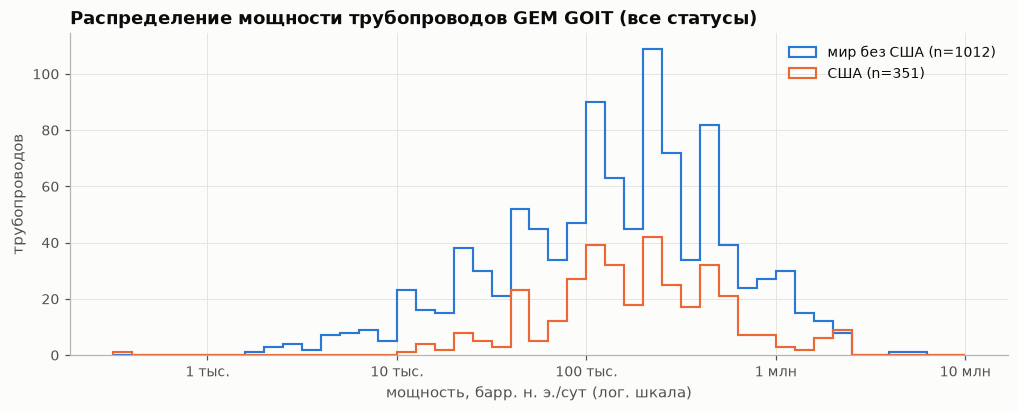

In [42]:
units = gem_all["capacity_units"].fillna("(нет)").value_counts()
print("Единицы capacity:", units.to_dict())
print(f"capacity_boed пропущен: весь мир {gem_all['capacity_boed'].isna().mean() * 100:.1f}%, США {gem_us['capacity_boed'].isna().mean() * 100:.1f}%; "
      f"медиана: весь мир {gem_all['capacity_boed'].median() / 1e3:.0f} тыс., США {gem_us['capacity_boed'].median() / 1e3:.0f} тыс. боэ/сут")
fig, ax = plt.subplots(figsize=(11, 3.8))
bins = np.linspace(2.5, 7, 46)
for i, (lab, d) in enumerate([("мир без США", gem_all[~gem_all["is_us"]]), ("США", gem_all[gem_all["is_us"]])]):
    v = d["capacity_boed"].dropna().astype(float)
    ax.hist(np.log10(v), bins=bins, histtype="step", linewidth=1.4, color=u.SERIES[i], label=f"{lab} (n={len(v)})")
ax.set_xticks([3, 4, 5, 6, 7])
ax.set_xticklabels(["1 тыс.", "10 тыс.", "100 тыс.", "1 млн", "10 млн"])
ax.set_xlabel("мощность, барр. н. э./сут (лог. шкала)")
ax.set_ylabel("трубопроводов")
ax.set_title("Распределение мощности трубопроводов GEM GOIT (все статусы)")
ax.legend()
plt.show()

### 6.1 Качество временной реконструкции (США, нефть)

In [43]:
t = gem_t
tq = {
    "строк (нефтяные трубопроводы США)": len(t),
    "source_snapshot": t["source_snapshot"].unique().tolist(),
    "historical_interval_quality": t["historical_interval_quality"].unique().tolist(),
    "last_updated: min / max": f"{t['last_updated'].min():%Y-%m-%d} / {t['last_updated'].max():%Y-%m-%d}",
    "без active_from_year": int(t["active_from_year"].isna().sum()),
    "  из них operating": int((t["active_from_year"].isna() & t["status"].eq("operating")).sum()),
    "с active_to_year": int(t["active_to_year"].notna().sum()),
    "cancelled/shelved с годом старта": int((t["status"].isin(["cancelled", "shelved"]) & t["start_year1"].notna()).sum()),
    "active_to_year < active_from_year": int((t["active_to_year"] < t["active_from_year"]).sum()),
    "active_to_year == active_from_year": int((t["active_to_year"] == t["active_from_year"]).sum()),
    "retired без stop_year": int((t["status"].eq("retired") & t["stop_year"].isna()).sum()),
    "старт позже текущего года": int((t["active_from_year"] > SNAPSHOT.year).sum()),
    "с геометрией маршрута": int(t["route_has_geometry"].sum()),
}
pd.Series(tq, name="значение").to_frame()

,значение
строк (нефтяные трубопроводы США),315
source_snapshot,[GOIT 2026-06]
historical_interval_quality,[year_level_approximation]
last_updated: min / max,2021-08-17 / 2026-06-13
без active_from_year,60
из них operating,36
с active_to_year,56
cancelled/shelved с годом старта,32
active_to_year < active_from_year,12
active_to_year == active_from_year,10


Реконструкция: {2015: {'сегментов': 108, 'мощность, млн б/с': 29.7}, 2020: {'сегментов': 189, 'мощность, млн б/с': 49.5}, 2026: {'сегментов': 206, 'мощность, млн б/с': 54.7}}
Сумма capacity_boed действующих (status=operating) нефтяных сегментов США: 57.3 млн б/с


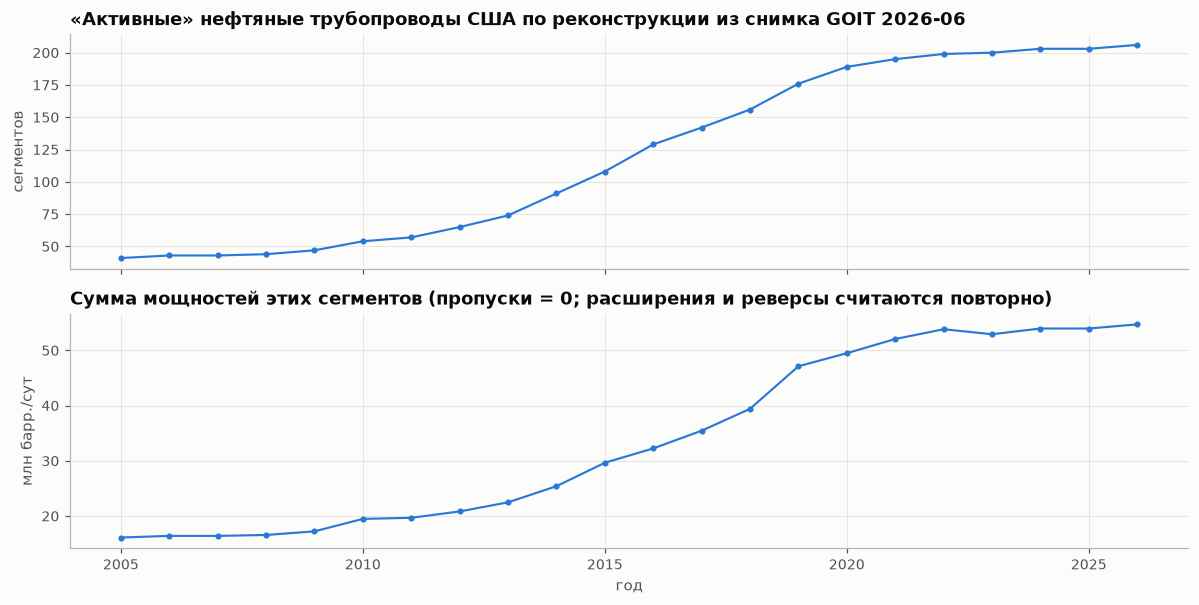

In [44]:
yrs = np.arange(2005, SNAPSHOT.year + 1)
act_n, act_cap = [], []
for y in yrs:
    m = (t["active_from_year"] <= y) & (t["active_to_year"].isna() | (t["active_to_year"] > y))
    m = m.fillna(False)
    act_n.append(int(m.sum()))
    act_cap.append(float(t.loc[m, "capacity_boed"].fillna(0).sum()) / 1e6)
act_s = pd.DataFrame({"сегментов": act_n, "мощность, млн б/с": act_cap}, index=yrs)
print("Реконструкция:", act_s.loc[[2015, 2020, SNAPSHOT.year]].round(1).to_dict("index"))
print(f"Сумма capacity_boed действующих (status=operating) нефтяных сегментов США: {t.loc[t['status'].eq('operating'), 'capacity_boed'].sum() / 1e6:.1f} млн б/с")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True)
axes[0].plot(yrs, act_n, marker="o", markersize=3, color=u.SERIES[0])
axes[0].set_ylabel("сегментов")
axes[0].set_title("«Активные» нефтяные трубопроводы США по реконструкции из снимка GOIT 2026-06")
axes[1].plot(yrs, act_cap, marker="o", markersize=3, color=u.SERIES[0])
axes[1].set_ylabel("млн барр./сут")
axes[1].set_title("Сумма мощностей этих сегментов (пропуски = 0; расширения и реверсы считаются повторно)")
axes[1].set_xlabel("год")
fig.tight_layout()
plt.show()

### 6.2 Собственники: дубликаты и концентрация

In [45]:
dup = own_all[own_all.duplicated(keep=False)]
dup_proj = gem_all.set_index("project_id").reindex(dup["project_id"].unique())
own_qa = {
    "строк (весь мир)": len(own_all),
    "полных дубликатов строк": int(own_all.duplicated().sum()),
    "затронуто project_id": int(dup["project_id"].nunique()),
    "  из них в США": int(dup_proj["is_us"].fillna(False).sum()),
    "страны затронутых проектов (топ)": dup_proj["countries_or_areas"].value_counts().head(3).to_dict(),
    "дубликатов в ownership_us / snapshot": f"{int(own_us.duplicated().sum())} / {int(own_snap.drop(columns=['ownership_snapshot', 'point_in_time_historical_safe']).duplicated().sum())}",
    "project_id собственности, нет в pipelines_all": int(own_all.loc[~own_all["project_id"].isin(gem_all["project_id"]), "project_id"].nunique()),
    "трубопроводов без строк собственности": int((~gem_all["project_id"].isin(own_all["project_id"])).sum()),
    "ownership_snapshot / point_in_time_historical_safe": f"{own_snap['ownership_snapshot'].unique().tolist()} / {own_snap['point_in_time_historical_safe'].unique().tolist()}",
}
pd.Series(own_qa, name="значение").to_frame()

,значение
строк (весь мир),23996
полных дубликатов строк,69
затронуто project_id,67
из них в США,0
страны затронутых проектов (топ),"{'China': 45, 'Russia': 7, 'Kazakhstan': 4}"
дубликатов в ownership_us / snapshot,0 / 0
"project_id собственности, нет в pipelines_all",62
трубопроводов без строк собственности,305
ownership_snapshot / point_in_time_historical_safe,['2026-10'] / [False]


In [46]:
o = own_all.drop_duplicates()
depth = o["ownership_path"].str.count("->")
owned_ids = set(ent_own["subject_entity_id"])
path_qa = {
    "глубина пути (число «->»): медиана / max": f"{int(depth.median())} / {int(depth.max())}",
    "строк с share = NA, %": round(o["share"].isna().mean() * 100, 1),
    "parent сам принадлежит другой entity, % строк": round(o["parent_gem_entity_id"].isin(owned_ids).mean() * 100, 1),
    "строк с parent = small shareholder(s) / natural person(s) / unknown": int(o["parent"].isin(["small shareholder(s)", "natural person(s)", "unknown"]).sum()),
    "сумма share по проекту, медиана %": round(float(o.groupby("project_id")["share"].sum().median()), 1),
}
display(pd.Series(path_qa, name="значение").to_frame())


def parse_parents(s):
    """'Enbridge Inc [50.00%]; Enterprise Products Partners LP [50.00%]' -> [(имя, доля)]."""
    out = []
    for part in str(s).split(";"):
        m = re.match(r"\s*(.+?)\s*\[([\d.]+)%\]\s*$", part)
        if m:
            out.append((m.group(1), float(m.group(2))))
    return out


op_us = gem_us[gem_us["status"].eq("operating")].copy()
pp = op_us[["project_id", "parent", "capacity_boed"]].assign(pairs=op_us["parent"].map(parse_parents)).explode("pairs")
print(f"Действующие трубопроводы США: {len(op_us)}; без распознанной доли parent: {int(pp['pairs'].isna().sum())}; "
      f"без мощности: {int(op_us['capacity_boed'].isna().sum())}")
pp = pp.dropna(subset=["pairs"])
pp["parent_name"] = pp["pairs"].str[0]
pp["share"] = pp["pairs"].str[1]
pp["cap_owned"] = pp["share"] / 100 * pp["capacity_boed"].astype(float).fillna(0)
par = pp.groupby("parent_name").agg(сегментов=("project_id", "nunique"), мощность_тыс=("cap_owned", "sum"))
par["мощность_тыс"] /= 1e3
par["доля, %"] = par["мощность_тыс"] / par["мощность_тыс"].sum() * 100
par = par.sort_values("мощность_тыс", ascending=False)
print(f"Собственников (поле parent): {len(par)}; HHI по мощности с учётом долей: {(par['доля, %'] ** 2).sum():.0f}; "
      f"топ-5: {par['доля, %'].head(5).sum():.1f}%, топ-10: {par['доля, %'].head(10).sum():.1f}%")
par.head(12).round(1)

,значение
глубина пути (число «->»): медиана / max,4 / 17
"строк с share = NA, %",31.5
"parent сам принадлежит другой entity, % строк",47.9
строк с parent = small shareholder(s) / natural person(s) / unknown,5933
"сумма share по проекту, медиана %",200.0


Действующие трубопроводы США: 334; без распознанной доли parent: 92; без мощности: 63
Собственников (поле parent): 49; HHI по мощности с учётом долей: 886; топ-5: 55.5%, топ-10: 74.2%


,сегментов,мощность_тыс,"доля, %"
parent_name,,,
Enbridge Inc,43,11465.0,22.0
Enterprise Products Partners LP,46,5665.8,10.9
Plains All American Pipeline LP,33,4230.9,8.1
Energy Transfer LP,22,3792.2,7.3
Shell PLC,13,3778.6,7.3
MPLX LP,10,2844.3,5.5
Targa Resources Corp,6,1920.0,3.7
ONEOK Inc,17,1771.5,3.4
Sunoco LP,11,1627.0,3.1


In [47]:
ent_qa = {
    "entities": len(ent),
    "entity_id уникален": bool(ent["entity_id"].is_unique),
    "entity_ownership рёбер": len(ent_own),
    "subject/interested в entities, %": f"{ent_own['subject_entity_id'].isin(ent['entity_id']).mean() * 100:.1f} / {ent_own['interested_party_id'].isin(ent['entity_id']).mean() * 100:.1f}",
    "parent_gem_entity_id в entities, %": round(own_all["parent_gem_entity_id"].isin(ent["entity_id"]).mean() * 100, 1),
    "immediate_owner_id в entities, %": round(own_all["immediate_project_owner_gem_entity_id"].isin(ent["entity_id"]).mean() * 100, 1),
    "entities с заполненным us_eia": int(ent["us_eia"].notna().sum()),
    "  из них не «not found»": int((ent["us_eia"].notna() & ent["us_eia"].ne("not found")).sum()),
}
pd.Series(ent_qa, name="значение").to_frame()

,значение
entities,28741
entity_id уникален,True
entity_ownership рёбер,27792
"subject/interested в entities, %",100.0 / 100.0
"parent_gem_entity_id в entities, %",100.0
"immediate_owner_id в entities, %",100.0
entities с заполненным us_eia,19
из них не «not found»,17


**Вывод.**
- В GOIT 1 926 трубопроводов (1 634 нефтяных, 292 NGL), из них 421 в США (315 нефтяных, 106 NGL). В США
  действуют 334, отменены 55, предложены 14, строятся 12. Действующие трубопроводы США: 151,6 тыс. км и 66,9 млн боэ/сут
  суммарной мощности (у 18,9% мощность пропущена); в остальном мире — 290,7 тыс. км и 227,3 млн (32,4% пропусков).
  Исходные единицы мощности разнородны (bpd 746, mtpa 578, без единиц 563, ещё 7 видов); `capacity_boed`
  пропущен у 29,2% всех и у 16,6% американских трубопроводов. Медиана мощности — 160 тыс. боэ/сут (мир)
  и 185 тыс. (США).
- Временная реконструкция грубая. Все 315 строк помечены `year_level_approximation` и взяты из снимка GOIT
  2026-06 (`last_updated` от 2021-08-17 до 2026-06-13). У 60 строк нет года старта (из них 36 действующих —
  они выпадают из «активных» за все годы), у 32 отменённых/отложенных проектов год старта есть (плановый),
  у 12 конец интервала раньше начала, у 14 старт позже 2026 г. «Активных» сегментов по реконструкции 108 в 2015 г.,
  189 в 2020-м и 206 в 2026-м. Сумма мощностей сегментов не равна пропускной
  способности системы: у действующих нефтяных сегментов США она 57 млн б/с — в четыре раза больше добычи страны,
  потому что расширения, реверсы и лупинги — отдельные строки. Использовать только счётчики или мощности по
  неперекрывающимся маршрутам.
- Собственность: 69 полных дубликатов строк в `gem_pipeline_ownership_all` затрагивают 67 проектов, и все они
  вне США (Китай 45, Россия 7, Казахстан 4); в таблицах по США дубликатов нет. Важнее другое: таблица хранит
  пути владения, а не доли: глубина пути — медиана 4, максимум 17; у 31,5% строк доля пустая; 47,9% «parent»
  сами принадлежат другим компаниям; 5 933 строки — «small shareholder(s)» / «natural person(s)» / «unknown».
  Сумма долей по проекту в медиане 200%, суммировать доли нельзя.
- Концентрацию считаем по полю `parent` таблицы трубопроводов (доли прямых родителей). Действующие трубопроводы
  США с известными долями: 49 собственников, HHI 886, топ-5 — 55,5%, топ-10 — 74,2% (Enbridge 22,0%, Enterprise
  10,9%, Plains 8,1%, Energy Transfer 7,3%, Shell 7,3%). У 92 из 334 действующих трубопроводов доли
  «unknown %» — они не учтены.
- Снимок, а не точка во времени: `ownership_snapshot = 2026-10` и `point_in_time_historical_safe = False` во всех
  строках. Ссылочная целостность entity хорошая: 100% `parent_gem_entity_id` есть в `gem_entities`, `entity_id`
  уникален. Связи с EIA через GEM почти нет: поле `us_eia` заполнено реальным значением у 17 из 28 741 entity.

## 7. Кандидаты OSM

OSM-объекты собраны по четырём прямоугольникам (`REGION_BBOXES` в `overpass_client.py`): НПЗ — тег
`industrial=refinery`, резервуары — `man_made=storage_tank` с `content`/`substance` ∈ {crude, oil, petroleum}.
Прямоугольники захватывают часть Канады; ниже грубое правило «вне США» по координатам
(широта > 49°, или к востоку от 80° з. д. севернее 45°, или Онтарио у 79,5–80° з. д. севернее 43,3°).

In [48]:
def non_us(df):
    return (df["latitude"] > 49) | ((df["longitude"] > -80) & (df["latitude"] > 45)) | (
        df["longitude"].between(-80, -79.5) & (df["latitude"] > 43.3)
    )


def cluster_km(df, km=3.0):
    lat = np.radians(df["latitude"].to_numpy())
    lon = np.radians(df["longitude"].to_numpy())
    lab = np.full(len(df), -1)
    k = 0
    for i in range(len(df)):
        if lab[i] >= 0:
            continue
        d = 6371 * np.hypot(lat - lat[i], (lon - lon[i]) * np.cos(lat[i]))
        lab[(d < km) & (lab < 0)] = k
        k += 1
    return lab


osm_ref["вне_США"] = non_us(osm_ref)
osm_tank["вне_США"] = non_us(osm_tank)
osm_ref["кластер"] = cluster_km(osm_ref)
osm_q = pd.DataFrame(
    {
        "объектов": [len(osm_ref), len(osm_tank)],
        "с name, %": [osm_ref["name"].notna().mean() * 100, osm_tank["name"].notna().mean() * 100],
        "с operator, %": [osm_ref["operator"].notna().mean() * 100, osm_tank["operator"].notna().mean() * 100],
        "вне США (грубо)": [int(osm_ref["вне_США"].sum()), int(osm_tank["вне_США"].sum())],
        "дубликатов osm_type+osm_id": [int(osm_ref.duplicated(["osm_type", "osm_id"]).sum()), int(osm_tank.duplicated(["osm_type", "osm_id"]).sum())],
    },
    index=["НПЗ-кандидаты", "резервуары-кандидаты"],
)
display(osm_q.round(1))
display(pd.DataFrame({"НПЗ": osm_ref["region"].value_counts(), "резервуары": osm_tank["region"].value_counts()}))
us_ref = osm_ref[~osm_ref["вне_США"]]
print(f"НПЗ-кандидатов в США: {len(us_ref)}, площадок после склейки в радиусе 3 км: {us_ref['кластер'].nunique()}; "
      f"НПЗ в EIA {ref['report_year'].max()}: {int((ref['report_year'] == ref['report_year'].max()).sum())}")
print("Вне США:", osm_ref.loc[osm_ref["вне_США"], "name"].fillna("(без имени)").tolist())

,объектов,"с name, %","с operator, %",вне США (грубо),дубликатов osm_type+osm_id
НПЗ-кандидаты,85,74.1,47.1,6,0
резервуары-кандидаты,18470,0.1,1.2,50,0


,НПЗ,резервуары
region,,
east_coast,14,565
gulf_coast,24,1019
midcontinent,18,16736
west_coast,29,150


НПЗ-кандидатов в США: 79, площадок после склейки в радиусе 3 км: 58; НПЗ в EIA 2026: 124
Вне США: ['North Vancouver Liquid Waste Facility', 'Suncor - Burrard Terminal', 'Irving Oil Refinery', 'Petro-Canada Lubricants', '(без имени)', 'Énergie Valero - Raffinerie Jean-Gaulin']


In [49]:
tags = osm_tank["tags"].map(json.loads)
CUSHING = (35.985, -96.767)
dist_c = 111 * np.hypot(osm_tank["latitude"] - CUSHING[0], (osm_tank["longitude"] - CUSHING[1]) * np.cos(np.radians(CUSHING[0])))
print("content:", tags.map(lambda d: d.get("content")).value_counts(dropna=False).to_dict())
print("substance:", tags.map(lambda d: d.get("substance")).value_counts(dropna=False).to_dict())
print("osm_type:", osm_tank["osm_type"].value_counts().to_dict())
print(f"Резервуаров в радиусе 10 км от Кушинга: {int((dist_c < 10).sum())}, 25 км: {int((dist_c < 25).sum())}")
print("Частые operator:", osm_tank["operator"].value_counts().head(6).to_dict())

content: {'oil': 18460, nan: 9, 'petroleum': 1}
substance: {nan: 18150, 'oil': 320}
osm_type: {'node': 14528, 'way': 3942}
Резервуаров в радиусе 10 км от Кушинга: 2, 25 км: 2
Частые operator: {'Freeport Harbor Co. Ltd.': 103, 'Loop LLC': 22, 'Killiam Oil Co. LTD': 20, 'Mid Valley Pipeline Company LLC': 10, 'J.D. Streett & Co.': 10, 'Killiam Oil Co. LTD.': 9}


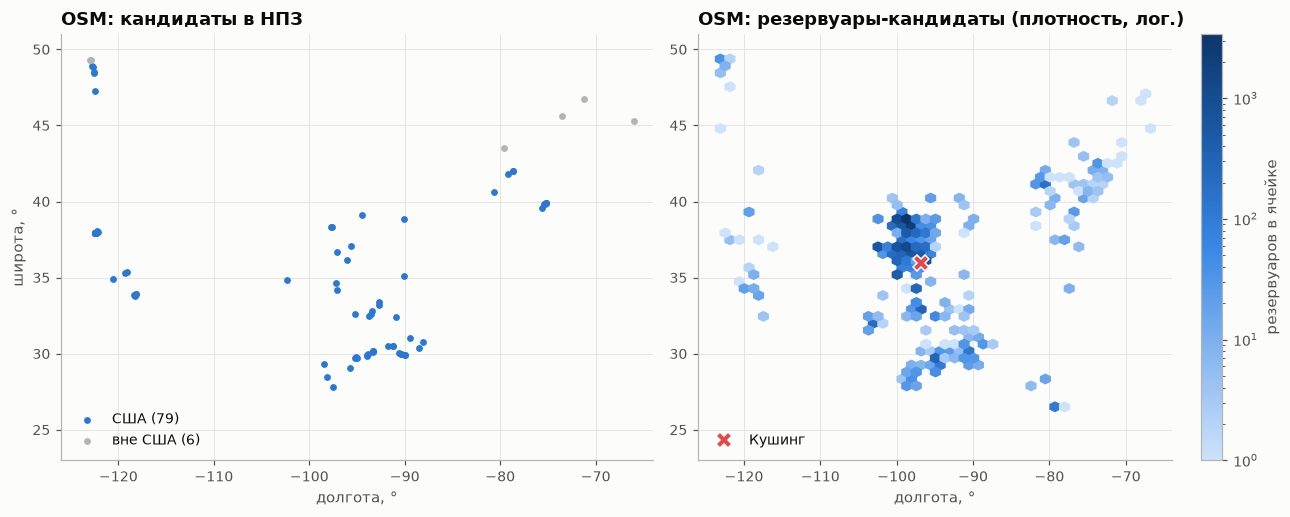

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
r_us = osm_ref[~osm_ref["вне_США"]]
r_non = osm_ref[osm_ref["вне_США"]]
axes[0].scatter(r_us["longitude"], r_us["latitude"], s=12, color=u.SERIES[0], label=f"США ({len(r_us)})")
axes[0].scatter(r_non["longitude"], r_non["latitude"], s=12, color=u.NEUTRAL, label=f"вне США ({len(r_non)})")
axes[0].set_title("OSM: кандидаты в НПЗ")
axes[0].set_xlabel("долгота, °")
axes[0].set_ylabel("широта, °")
axes[0].legend(loc="lower left")
hb = axes[1].hexbin(osm_tank["longitude"], osm_tank["latitude"], gridsize=45, bins="log", cmap=u.SEQUENTIAL, mincnt=1)
axes[1].plot(CUSHING[1], CUSHING[0], marker="X", color=u.SERIES[7], markeredgecolor="white", markersize=11, linestyle="none", label="Кушинг")
axes[1].set_title("OSM: резервуары-кандидаты (плотность, лог.)")
axes[1].set_xlabel("долгота, °")
axes[1].legend(loc="lower left")
fig.colorbar(hb, ax=axes[1], label="резервуаров в ячейке")
for ax in axes:
    ax.set_xlim(-126, -64)
    ax.set_ylim(23, 51)
fig.tight_layout()
plt.show()

In [51]:
cells = osm_tank.assign(lat1=osm_tank["latitude"].round(0), lon1=osm_tank["longitude"].round(0)).groupby(["lat1", "lon1"]).size()
top_cells = cells.sort_values(ascending=False).head(8)
print(f"Доля резервуаров в 8 самых плотных ячейках 1°×1°: {top_cells.sum() / len(osm_tank) * 100:.1f}%")
top_cells.rename("резервуаров").to_frame()

Доля резервуаров в 8 самых плотных ячейках 1°×1°: 62.6%


резервуаров
lat1 lon1               
39.0 -99.0          4158
38.0 -99.0          1470
     -98.0          1403
37.0 -99.0          1399
     -98.0          1000
     -100.0          782
36.0 -96.0           750
37.0 -97.0           597

**Вывод.**
- НПЗ-кандидатов 85: имя есть у 74,1%, оператор — у 47,1%. 6 объектов за пределами США (Канада, в том числе
  очистные сооружения North Vancouver и терминал Burrard). Оставшиеся 79 склеиваются в 58 площадок в радиусе
  3 км (крупные НПЗ, например Richmond, разбиты на десяток полигонов без имени), тогда как в EIA за 2026 г. 124 НПЗ.
  Полезны как источник координат для части НПЗ EIA (их нет в EIA вовсе), но сопоставление по имени придётся
  делать вручную или полуавтоматически. Заменить EIA как реестр они не могут.
- Резервуаров-кандидатов 18 470: имя есть у 0,1%, оператор — у 1,2%; 90,6% в прямоугольнике midcontinent, 62,6% в
  восьми ячейках 1°×1° — в основном центральный Канзас (39° с. ш., 99° з. д.: 4 158 штук). Это промысловые
  резервуары, а не терминалы. Возле Кушинга, крупнейшего хаба хранения, их всего 2 в радиусе 25 км. Для
  хранилищ/терминалов и для Кушинга OSM в этом виде бесполезен.

## 8. Готовность к графу

### 8.1 Ключи соединения

In [52]:
def norm_name(s):
    s = s.astype("string").str.upper().str.replace(r"[^A-Z0-9 ]", " ", regex=True)
    s = s.str.replace(r"\b(INC|CORP|CORPORATION|CO|COMPANY|LLC|L L C|LP|L P|PLC|LTD|LIMITED|USA|U S A|US|THE|HOLDINGS|GROUP)\b", " ", regex=True)
    return s.str.split().str.join(" ")


ent_names = set(norm_name(ent["name"]).dropna()) | set(norm_name(ent["full_name"]).dropna())
corp26 = pd.Series(ref.loc[ref["report_year"].eq(ref["report_year"].max()), "corporation"].unique())
ops25 = pd.Series(gom.loc[gom["production_date"].dt.year.eq(2025), "pf_operator"].unique())
owner_ids = gem_all["owner_entity_ids"].dropna().str.split(r"[;,]\s*", regex=True).explode().str.strip()
keys = pd.DataFrame(
    [
        ("complex_id_num + structure_number", "добыча залива → platform_history", f"{coords['latitude'].notna().mean() * 100:.1f}% сооружений"),
        ("complex_id_num", "BOEM current → BSEE platform_history", f"{boem_c.isin(bsee_all_c).mean() * 100:.1f}% точек"),
        ("segment_num", "history_events → offshore_pipelines", f"{pev['segment_num'].isin(pipes['segment_num']).mean() * 100:.1f}% событий"),
        ("segment_num", "offshore_pipelines → геометрия BOEM", f"{pipes['geometry_json'].notna().mean() * 100:.1f}% сегментов"),
        ("project_id", "gem_pipelines_all → ownership", f"{gem_all['project_id'].isin(own_all['project_id']).mean() * 100:.1f}% трубопроводов"),
        ("entity_id", "ownership.parent_gem_entity_id → entities", f"{own_all['parent_gem_entity_id'].isin(ent['entity_id']).mean() * 100:.1f}% строк"),
        ("entity_id", "pipelines.owner_entity_ids → entities", f"{owner_ids.isin(ent['entity_id']).mean() * 100:.1f}% ссылок"),
        ("refinery_key", "НПЗ год→год (стабильность)", f"{int((key_span == ref['report_year'].nunique()).sum())} из {ref['refinery_key'].nunique()} ключей во всех годах"),
        ("имя (нормализованное)", "EIA corporation → GEM entities", f"{norm_name(corp26).isin(ent_names).mean() * 100:.1f}% корпораций {ref['report_year'].max()}"),
        ("имя (нормализованное)", "BSEE pf_operator → GEM entities", f"{norm_name(ops25).isin(ent_names).mean() * 100:.1f}% операторов 2025"),
        ("координаты", "EIA НПЗ ↔ OSM / ураганы", "у EIA НПЗ нет координат (только штат и город)"),
    ],
    columns=["ключ", "связь", "покрытие"],
)
keys

,ключ,связь,покрытие
0,complex_id_num + structure_number,добыча залива → platform_history,99.9% сооружений
1,complex_id_num,BOEM current → BSEE platform_history,98.3% точек
2,segment_num,history_events → offshore_pipelines,100.0% событий
3,segment_num,offshore_pipelines → геометрия BOEM,81.4% сегментов
4,project_id,gem_pipelines_all → ownership,84.2% трубопроводов
5,entity_id,ownership.parent_gem_entity_id → entities,100.0% строк
6,entity_id,pipelines.owner_entity_ids → entities,87.4% ссылок
7,refinery_key,НПЗ год→год (стабильность),63 из 239 ключей во всех годах
8,имя (нормализованное),EIA corporation → GEM entities,41.2% корпораций 2026
9,имя (нормализованное),BSEE pf_operator → GEM entities,8.2% операторов 2025


### 8.2 Покрытие PADD 3 и Кушинга

In [53]:
PADD3_STATES = {"Texas", "Louisiana", "Mississippi", "Alabama", "Arkansas", "New Mexico"}
gu = gem_us.copy()
gu["padd3"] = gu["start_state_province"].isin(PADD3_STATES) | gu["end_state_province"].isin(PADD3_STATES)
cush = gu["start_location"].str.contains("Cushing", na=False) | gu["end_location"].str.contains("Cushing", na=False) | gu[
    "pipeline_name"
].str.contains("Cushing", na=False)
r_last = ref[ref["report_year"].eq(ref["report_year"].max())]
cov = pd.DataFrame(
    [
        ("НПЗ EIA (последний год)", f"{int(r_last['padd'].eq(3).sum())} НПЗ, {r_last.loc[r_last['padd'].eq(3), 'total_operable_capacity_bpcd'].sum() / r_last['total_operable_capacity_bpcd'].sum() * 100:.1f}% мощности",
         f"0 (НПЗ в Оклахоме: {', '.join(sorted(r_last.loc[r_last['state_name'].eq('Oklahoma'), 'site'].str.title().unique()))})"),
        ("Добыча BSEE (залив)", "весь шельф залива примыкает к побережью PADD 3", "—"),
        ("Трубопроводы GEM США", f"{int(gu['padd3'].sum())} из {len(gu)} касаются штатов PADD 3 (start/end)",
         f"{int(cush.sum())} упоминают Cushing, из них operating {int((cush & gu['status'].eq('operating')).sum())}"),
        ("OSM НПЗ", f"{int(osm_ref['region'].eq('gulf_coast').sum())} в прямоугольнике gulf_coast", "—"),
        ("OSM резервуары", f"{int(osm_tank['region'].eq('gulf_coast').sum())} в gulf_coast", f"{int((dist_c < 10).sum())} в радиусе 10 км"),
    ],
    columns=["источник", "PADD 3", "Кушинг"],
)
cov

,источник,PADD 3,Кушинг
0,НПЗ EIA (последний год),"52 НПЗ, 54.4% мощности","0 (НПЗ в Оклахоме: Ardmore, Ponca City, Tulsa ..."
1,Добыча BSEE (залив),весь шельф залива примыкает к побережью PADD 3,—
2,Трубопроводы GEM США,224 из 421 касаются штатов PADD 3 (start/end),"23 упоминают Cushing, из них operating 14"
3,OSM НПЗ,24 в прямоугольнике gulf_coast,—
4,OSM резервуары,1019 в gulf_coast,2 в радиусе 10 км


In [54]:
gu.loc[cush & gu["status"].eq("operating"), ["pipeline_name", "segment_name", "start_location", "end_location", "capacity_boed"]].sort_values(
    "capacity_boed", ascending=False
)

,pipeline_name,segment_name,start_location,end_location,capacity_boed
148,Seaway Oil Pipeline System,Seaway Twin,Cushing,Port Arthur,600000.0
397,Sunrise Pipeline System,<NA>,Midland,Cushing,350000.0
93,Seaway Oil Pipeline System,Mainline,Cushing,Houston,350000.0
139,Seaway Oil Pipeline System,Reversal,Cushing,Port Arthur,250000.0
392,Spearhead Oil Pipeline,<NA>,Pontiac,Cushing,193000.0
267,Cushing Connect Oil Pipeline,<NA>,<NA>,<NA>,160000.0
118,Keystone Oil Pipeline,Phase 2,Steele City,Cushing,156000.0
57,Seaway Oil Pipeline System,Expansion 2,Cushing,Port Arthur,100000.0
247,Borger Express Pipeline,<NA>,Cushing,Hutchinson County,90000.0
316,Hawthorn Pipeline,<NA>,Stroud,Cushing,90000.0


### 8.3 Типы узлов и рёбер

In [55]:
nodes = pd.DataFrame(
    [
        ("Platform / Complex", "bsee_platform_history, boem_platforms_current", "complex_id_num, structure_number", f"{len(plat)} сооружений, {len(bsee_current_c)} действующих комплексов", "install/removal dates — исторически"),
        ("Pipeline segment (офшор)", "bsee_offshore_pipelines", "segment_num", f"{len(pipes)} сегментов", "статус — текущий; история — events"),
        ("Pipeline (оншор)", "gem_pipelines_us / gem_oil_pipelines_temporal", "project_id", f"{len(gem_us)} США, {len(gem_t)} нефтяных", "годовая аппроксимация из снимка 2026-06"),
        ("Refinery", "eia_refineries_model_ready", "refinery_key (нестабилен), site", f"{r_last.shape[0]} НПЗ в {ref['report_year'].max()}", "годовой снимок, лаг 1 год"),
        ("Company", "gem_entities; pf_operator; corporation", "entity_id; имена", f"{len(ent)} entities", "снимок собственности 2026"),
        ("Region (PADD, Cushing)", "padd в EIA НПЗ; штаты GEM; прямоугольник залива", "padd, state", "PADD 1–5", "статичен"),
        ("Storm (шок)", "nhc_hurdat2_atlantic_2015_2025", "storm_id", f"{hur['storm_id'].nunique()} штормов", "final best track, не point-in-time"),
    ],
    columns=["узел", "таблицы", "ключ", "объём", "время"],
)
edges = pd.DataFrame(
    [
        ("Company —operates→ Complex", "bsee_production_by_structure (pf_operator, помесячно)"),
        ("Complex —produces→ Region(PADD 3)", "добыча bopd, помесячно, лаг публикации"),
        ("Complex —connected_by→ Pipeline segment", "orig_id_name / dest_id_name (текстовые, нужен разбор)"),
        ("Company —owns(share)→ Pipeline", "gem_pipeline_ownership_* (снимок)"),
        ("Company —owns→ Company", "gem_entity_ownership"),
        ("Company —operates→ Refinery", "corporation/company_name в EIA (матчинг имён с GEM)"),
        ("Refinery —located_in→ Region", "padd, state_name"),
        ("Pipeline —connects→ Region / Cushing", "start/end_state_province, start/end_location GEM"),
        ("Storm —hits→ Complex / Refinery", "треки HURDAT + координаты (у НПЗ координат нет)"),
    ],
    columns=["ребро", "источник"],
)
display(nodes)
edges

,узел,таблицы,ключ,объём,время
0,Platform / Complex,"bsee_platform_history, boem_platforms_current","complex_id_num, structure_number","7092 сооружений, 1061 действующих комплексов",install/removal dates — исторически
1,Pipeline segment (офшор),bsee_offshore_pipelines,segment_num,21314 сегментов,статус — текущий; история — events
2,Pipeline (оншор),gem_pipelines_us / gem_oil_pipelines_temporal,project_id,"421 США, 315 нефтяных",годовая аппроксимация из снимка 2026-06
3,Refinery,eia_refineries_model_ready,"refinery_key (нестабилен), site",124 НПЗ в 2026,"годовой снимок, лаг 1 год"
4,Company,gem_entities; pf_operator; corporation,entity_id; имена,28741 entities,снимок собственности 2026
5,"Region (PADD, Cushing)",padd в EIA НПЗ; штаты GEM; прямоугольник залива,"padd, state",PADD 1–5,статичен
6,Storm (шок),nhc_hurdat2_atlantic_2015_2025,storm_id,202 штормов,"final best track, не point-in-time"


,ребро,источник
0,Company —operates→ Complex,"bsee_production_by_structure (pf_operator, пом..."
1,Complex —produces→ Region(PADD 3),"добыча bopd, помесячно, лаг публикации"
2,Complex —connected_by→ Pipeline segment,"orig_id_name / dest_id_name (текстовые, нужен ..."
3,Company —owns(share)→ Pipeline,gem_pipeline_ownership_* (снимок)
4,Company —owns→ Company,gem_entity_ownership
5,Company —operates→ Refinery,corporation/company_name в EIA (матчинг имён с...
6,Refinery —located_in→ Region,"padd, state_name"
7,Pipeline —connects→ Region / Cushing,"start/end_state_province, start/end_location GEM"
8,Storm —hits→ Complex / Refinery,треки HURDAT + координаты (у НПЗ координат нет)


**Вывод.**
- Хорошие ключи: добыча → платформы (99,9% сооружений по `complex_id_num` + `structure_number`), события →
  сегменты (100% по `segment_num`), собственность → entities (100% по `entity_id`), трубопроводы GEM →
  собственность (84,2% по `project_id`; 62 `project_id` из собственности отсутствуют в `gem_pipelines_all`).
  Ссылки `owner_entity_ids` трубопроводов находятся в `gem_entities` на 87,4%.
- Слабые места: стабильного `refinery_key` нет (63 из 239), у НПЗ EIA нет координат, а компании между источниками
  связываются только по именам. Точное совпадение нормализованного имени с GEM — 41,2% корпораций EIA и 8,2%
  операторов BSEE, то есть рёбра Company–Refinery и Company–Complex потребуют словаря соответствий.
- PADD 3 покрыт хорошо: 52 НПЗ (54,4% мощности США в 2026), весь шельф залива, 224 из 421 трубопроводов GEM в США
  касаются штатов PADD 3. Кушинг покрыт плохо: НПЗ там нет, резервуаров OSM 2, есть только 23 трубопровода GEM
  с «Cushing» в начале/конце маршрута (14 действующих: Seaway, Sunrise, Spearhead, Keystone, Pony Express и др.).
- Чего нет: реестра хранилищ/терминалов (в том числе ёмкостей Кушинга), экспортных терминалов, оншорной добычи
  по бассейнам, недельных/суточных данных об остановках на шельфе (BSEE shut-in statistics) и недельных
  простоев НПЗ, исторической (point-in-time) собственности, координат НПЗ, сезона ураганов 2026 и оперативных
  advisory NHC.

## Итоги

**Ключевые находки**
- Шельф Мексиканского залива даёт 1,5–2,0 млн б/с (14,4% добычи США в 2025 г., 18,3% в 2016-м). Добыча растёт при
  быстром выводе инфраструктуры: действующих сооружений 1 301 против 2 439 в 2014 г., комплексов с нефтью
  305 против 879. Концентрация растёт: HHI операторов 1 092 → 1 625, топ-5 — 81,5%; 12 комплексов дают половину нефти.
- Ураганы — главный физический шок этого слоя: месяцы с ураганом кат. 3–5 в прямоугольнике добычи в среднем
  −19,8% к медиане, худшие −37,7% (2020-10) и −37,4% (2021-09). Недобор по Ida — 26 млн барр. по BSEE и 27 по
  недельной оценке EIA. Событий мало: 12 ураганов за 2015–2025, 0 в 2022 и 2025.
- Валовые падения мощности НПЗ на площадках за 2020–2026 — около 1,7 млн б/с (12 закрытий/конверсий), чистое
  снижение от пика 2020 г. — 816 тыс. б/с (18 976 → 18 160); PADD 3 — 54% мощности. Собственность трубопроводов США умеренно концентрирована (HHI 886, Enbridge 22%).

**Качество данных**
- `bsee_production_*`: в таблице есть регионы P (Тихий океан) и Y (Аляска) — фильтровать по `region_code == "G"`;
  в таблице по комплексам региона нет. 2026-09 неполный (176 строк из ~586, 239 из ~2 000 тыс. б/с). Ступенька −138
  строк в 2024-02. Агрегаты комплекс/сооружение совпадают точно.
- `bsee_pipeline_history_events.history_date`: 9 значений вне диапазона [1942, 2026-11-04] (0018-04-15 … 7001-07-02,
  опечатки в годе: сегменты 10376, 11167, 12374, 19050, 19096, 20183, 20343, 20465, 20532); у 12 572 событий пустой код,
  у 779 — код вне справочника.
- `bsee_offshore_*pipelines`: `aban_date` = 1870-03-01 у 10 сегментов (500090–501198; 3 нефтяных),
  `ppl_const_date` = 1903-04-23 у сегмента 9854, `prpsl_con_dt` пуст полностью, `aban_date < approved_date` у 29;
  длины: 2 236 пропусков, 1 007 нулей, выброс 1 664 км (сегмент 17364); геометрии нет у 18,6% сегментов;
  1 `DRFT` и 23 пустых статуса.
- HURDAT2: `point_in_time_safe = False` и `data_status = final_best_track` у всех 6 223 точек; 179 внесрочных точек;
  сезона 2026 нет.
- EIA refinery: `refinery_key` нестабилен (239 ключей, 63 сквозных), location key меняется при переименовании
  площадок; простой определяется только через импутированный 0; координат нет.
- GEM: 69 дубликатов в `gem_pipeline_ownership_all` (67 проектов, все вне США); таблицы собственности — пути
  владения (сумма долей по проекту в медиане 200%), а не аддитивные доли; интервалы активности —
  `year_level_approximation` из снимка 2026-06 (60 без года старта, 12 с концом раньше начала); мощность пропущена у 16,6%
  американских трубопроводов, сумма мощностей двойная из-за расширений.
- OSM: резервуары почти без имён (0,1%), в основном промысловые в Канзасе, у Кушинга 2 штуки; 6 НПЗ-кандидатов
  вне США. В папке 21 файл, а не 25.

**Следствия для модели**
- Недельный признак шока: «шторм/ураган в прямоугольнике добычи (25,6–30,7° с. ш., 97,5–87,3° з. д.) за неделю
  отчёта» и максимальная категория, лучше с весом по добыче комплексов в зоне ветра. Вес брать из BSEE с лагом
  ≥ 2 месяцев (или из заранее зафиксированного года), а не из текущего месяца.
- Best track не является point-in-time. Для честного бэктеста нужны оперативные advisory; если оставлять HURDAT2,
  использовать только положение и грубую категорию и прямо отметить это как допущение.
- Месячная добыча BSEE не годится как недельный признак без интерполяции, а недельная `crude_production` EIA выходит
  в том же релизе, что и таргет, — её лаг t−1 уже содержит информацию об остановке, которая ещё продолжается.
- Мощности НПЗ — медленный годовой признак с лагом; правило «1 января следующего года» лишает 2015 г. данных
  (52 релиза). Закрытия 2021 и 2026 гг. — ступеньки, которые можно задать отдельными событиями.
- Для графа сразу готовы Platform/Complex (BSEE), Pipeline (BSEE, GEM), Company (GEM entities), Storm (HURDAT).
  Refinery требует стабильного ID и координат, Company — словаря имён EIA/BSEE ↔ GEM, а для Кушинга нужен
  отдельный источник по хранилищам; собственность — только как статичный снимок 2026 г.